In [7]:
# ── Cell 1: imports, credentials, and one backend per QPU ─────────────────────
import os
import re
import json
import pathlib
from collections import Counter

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from iqm.qiskit_iqm import IQMProvider

# 1. Load all variables from .env into the environment
load_dotenv(override=True)

# 2. Retrieve them into Python variables
server_url = os.getenv("IQM_SERVER_URL")
qpu_1 = os.getenv("QUANTUM_COMPUTER_1")  # "garnet"
qpu_2 = os.getenv("QUANTUM_COMPUTER_2")  # "sirius"
qpu_3 = os.getenv("QUANTUM_COMPUTER_3")  # "emerald"
qpu_names = [q for q in (qpu_1, qpu_2, qpu_3) if q]

# 3. Connect to every QPU (IQMProvider reads IQM_TOKEN from os.environ — do NOT pass token=...)
#    use_metrics=True loads calibration data into backend.target for noise-aware transpilation.
providers, backends = {}, {}
for name in qpu_names:
    try:
        providers[name] = IQMProvider(server_url, quantum_computer=name)
        try:
            backends[name] = providers[name].get_backend(use_metrics=True)
        except Exception as err:
            print(f"[{name}] use_metrics=True failed ({err}); connecting without metrics")
            backends[name] = providers[name].get_backend()
        print(f"Connected to {name}:", backends[name].name, "| Qubits:", backends[name].num_qubits)
    except Exception as err:
        print(f"[{name}] could not connect: {err}")

# Keep the original single-backend names working for code that already uses them
provider, backend_iqm = providers.get(qpu_1), backends.get(qpu_1)

Connected to garnet: garnet | Qubits: 20
Connected to sirius: sirius | Qubits: 16


Missing duration for cz.slepian_crf.QB50__QB51
Missing metric 'fidelity' (with suffix :par=d2) for cz.slepian_crf.QB50__QB51


Connected to emerald: emerald | Qubits: 54


In [8]:
# ── Cell 2: coupling map of each connected QPU ────────────────────────────────
def component_key(name):
    """Sort QB1 < QB2 < ... < QB10, with any resonator after the qubits."""
    digits = re.sub(r"\D", "", name)
    return (not name.startswith("QB"), int(digits) if digits else 0, name)


def extract_topology(backend):
    """Physical couplers (by qubit name) plus the transpiler's coupling map (by index)."""
    dqa = backend.architecture  # gates and loci of the active calibration set
    qubits = sorted(dqa.qubits, key=component_key)
    resonators = sorted(dqa.computational_resonators, key=component_key)

    def undirected(loci):
        return sorted({tuple(sorted(l, key=component_key)) for l in loci},
                      key=lambda p: tuple(map(component_key, p)))

    cz_couplers = undirected(dqa.gates["cz"].loci) if "cz" in dqa.gates else []
    graph = nx.Graph()
    graph.add_nodes_from(qubits, kind="qubit")
    graph.add_nodes_from(resonators, kind="resonator")
    graph.add_edges_from(cz_couplers)

    coupling_map = [list(e) for e in backend.coupling_map.get_edges()]
    return {
        "qubits": qubits,
        "resonators": resonators,
        "cz_couplers": cz_couplers,
        "graph": graph,
        "coupling_map": coupling_map,
        "coupling_map_names": [[backend.index_to_qubit_name(a), backend.index_to_qubit_name(b)]
                               for a, b in coupling_map],
        "default_impl": {g: info.default_implementation for g, info in dqa.gates.items()},
        "calibration_set_id": str(dqa.calibration_set_id),
    }


topologies = {}
for name, backend in backends.items():
    topo = topologies[name] = extract_topology(backend)
    degrees = Counter(d for n, d in topo["graph"].degree() if n in topo["qubits"])
    print("=" * 70)
    print(f"{name}: {len(topo['qubits'])} qubits | calibration set {topo['calibration_set_id']}")
    print(f"  native ops      : {sorted(backend.operation_names)}")
    print(f"  CZ couplers     : {len(topo['cz_couplers'])} | qubit degrees {dict(sorted(degrees.items()))}")
    if topo["resonators"]:
        print(f"  resonators      : {topo['resonators']} — every CZ goes through one; the transpiler "
              f"map below is {len(topo['coupling_map'])} virtual qubit-qubit edges (MOVE-CZ-MOVE)")
    print(f"  coupling map    : {topo['coupling_map']}")

garnet: 20 qubits | calibration set ea681de1-9661-41e5-bd6f-cb524fa056a6
  native ops      : ['cz', 'delay', 'id', 'if_else', 'measure', 'r', 'reset']
  CZ couplers     : 30 | qubit degrees {2: 8, 3: 4, 4: 8}
  coupling map    : [[1, 0], [1, 4], [3, 0], [3, 2], [3, 4], [3, 8], [5, 4], [5, 6], [5, 10], [7, 2], [7, 8], [7, 12], [9, 4], [9, 8], [9, 10], [9, 14], [11, 6], [11, 10], [11, 16], [13, 8], [13, 12], [13, 14], [13, 17], [15, 10], [15, 14], [15, 16], [15, 19], [18, 14], [18, 17], [18, 19]]
sirius: 16 qubits | calibration set 32dc2a78-9585-4ce6-9a37-95f53c7ff92c
  native ops      : ['cz', 'delay', 'id', 'if_else', 'measure', 'r', 'reset']
  CZ couplers     : 16 | qubit degrees {1: 16}
  resonators      : ['COMPR1'] — every CZ goes through one; the transpiler map below is 240 virtual qubit-qubit edges (MOVE-CZ-MOVE)
  coupling map    : [[0, 1], [1, 0], [0, 2], [2, 0], [0, 3], [3, 0], [0, 4], [4, 0], [0, 5], [5, 0], [0, 6], [6, 0], [0, 7], [7, 0], [0, 8], [8, 0], [0, 9], [9, 0], [0, 

garnet: metrics from live, measured 2026-11-21T02-43-01, 598 observations
t1_us            38.07829
t2_us            10.25867
t2_echo_us       22.03072
f_1q              0.99955
f_readout         0.98140
e_0to1            0.01130
e_1to0            0.02420
qndness           0.96865
leakage           0.00361
f_readout_alt     0.98365
init_error        0.00682
worst readout : {'QB5': 0.9645, 'QB19': 0.97, 'QB14': 0.9711}
worst CZ      : {'QB10-QB11': 0.9909, 'QB10-QB15': 0.9912, 'QB14-QB15': 0.9922}
sirius: metrics from live, measured 2026-11-21T05-48-09, 468 observations
t1_us            25.83259
t2_us             9.78679
t2_echo_us       24.12775
f_1q              0.99876
f_readout         0.98050
e_0to1            0.00720
e_1to0            0.02920
qndness               NaN
leakage               NaN
f_readout_alt     0.98130
init_error        0.00312
worst readout : {'QB5': 0.9772, 'QB2': 0.9776, 'QB8': 0.979}
worst CZ      : {'QB19-COMPR1': 0.9723, 'QB21-COMPR1': 0.9737, 'QB15-COMPR1':

In [11]:
# ── Cell 3: calibration metrics per qubit and per coupler (no circuits run) ───
# Source: IQM's own calibration/benchmarking, published as a "quality metric set"
# for each calibration set. Only Garnet and Emerald are used from here on.
QEC_QPUS = [q for q in (qpu_1, qpu_3) if q in backends]
SNAPSHOT_DIR = pathlib.Path("calibration_snapshots")
SNAPSHOT_DIR.mkdir(exist_ok=True)


def fetch_quality_metrics(backend):
    """Quality metrics for the exact calibration set this backend runs with."""
    cal_id = backend.architecture.calibration_set_id
    qms = json.loads(backend.client.get_quality_metric_set(calibration_set_id=cal_id).model_dump_json())
    if str(qms.get("describes_id")) != str(cal_id):
        print(f"  warning: metrics describe {qms.get('describes_id')}, backend uses {cal_id}")
    return qms


def parse_observations(qms):
    """One row per observation: family, implementation, locus, metric, value, uncertainty."""
    rows = []
    for obs in qms["observations"]:
        if obs.get("invalid"):
            continue
        base, *params = obs["dut_field"].split(":")
        parts = base.split(".")
        for i, seg in enumerate(parts):
            locus = seg.split("__")
            if all(re.fullmatch(r"QB\d+", t) for t in locus):
                break
        else:
            continue  # not a per-qubit or per-pair observation
        prefix = parts[:i]
        family, impl = ((".".join(prefix[:3]), ".".join(prefix[3:])) if prefix[0] == "metrics"
                        else (".".join(prefix), ""))
        rows.append(dict(family=family, impl=impl, locus=tuple(sorted(locus, key=component_key)),
                         n=len(locus), metric=".".join(parts[i + 1:]), params=":".join(params),
                         value=obs["value"], unc=obs.get("uncertainty")))
    return pd.DataFrame(rows)


def default_impl(backend, gate, locus):
    """Implementation the QPU actually uses for this gate on this locus (handles per-locus overrides)."""
    info = backend.architecture.gates.get(gate)
    if info is None:
        return None
    for order in (locus, locus[::-1]):
        try:
            return info.get_default_implementation(tuple(order))
        except Exception:
            continue
    return info.default_implementation


def pick(raw, backend, family, metric, n, gate=None, params=""):
    """{locus: (value, uncertainty, impl)}; params="" means no qualifiers, None means any."""
    sel = raw[(raw.family == family) & (raw.metric == metric) & (raw.n == n)]
    if params is not None:
        sel = sel[sel.params.str.startswith(params)] if params else sel[sel.params == ""]
    out = {}
    for locus, grp in sel.groupby("locus"):
        want = default_impl(backend, gate, locus) if gate else None
        impls = sorted(set(grp.impl))
        best = (next((i for i in impls if i == want), None)
                or next((i for i in impls if want and i.startswith(want)), None) or impls[0])
        row = grp[grp.impl == best].iloc[0]
        out[locus] = (row.value, row.unc, best)
    return out


def target_durations_ns(backend, op):
    """Gate/readout durations from backend.target (present when connected with use_metrics=True)."""
    if op not in backend.target:
        return {}
    return {tuple(sorted((backend.index_to_qubit_name(i) for i in qargs), key=component_key)):
            props.duration * 1e9
            for qargs, props in backend.target[op].items() if props and props.duration}


def build_tables(raw, backend, topo):
    q = pd.DataFrame(index=pd.Index(topo["qubits"], name="qubit"))
    p = pd.DataFrame(index=pd.MultiIndex.from_tuples(topo["cz_couplers"], names=["a", "b"]))

    def put(table, col, picked, scale=1.0, unc=False, impl=False):
        key = (lambda k: k[0]) if table is q else (lambda k: k)
        table[col] = pd.Series({key(k): v[0] * scale for k, v in picked.items()}, dtype=float)
        if unc:
            table[col + "_unc"] = pd.Series({key(k): (v[1] or float("nan")) * scale
                                             for k, v in picked.items()}, dtype=float)
        if impl:
            table[col + "_impl"] = pd.Series({key(k): v[2] for k, v in picked.items()})

    m = default_impl(backend, "measure", ())
    model = "characterization.model"
    q["idx"] = [backend.qubit_name_to_index(n) for n in q.index]  # use for initial_layout
    put(q, "t1_us", pick(raw, backend, model, "t1_time", 1), 1e6, unc=True)
    put(q, "t2_us", pick(raw, backend, model, "t2_time", 1), 1e6, unc=True)
    put(q, "t2_echo_us", pick(raw, backend, model, "t2_echo_time", 1), 1e6, unc=True)
    put(q, "f_1q", pick(raw, backend, "metrics.rb.prx", "fidelity", 1, "prx", None), unc=True, impl=True)
    put(q, "f_readout", pick(raw, backend, "metrics.ssro.measure", "fidelity", 1, "measure"), unc=True)
    put(q, "e_0to1", pick(raw, backend, "metrics.ssro.measure", "error_0_to_1", 1, "measure"), unc=True)
    put(q, "e_1to0", pick(raw, backend, "metrics.ssro.measure", "error_1_to_0", 1, "measure"), unc=True)
    put(q, "qndness", pick(raw, backend, "metrics.rrc.measure", "qndness", 1, "measure"), unc=True)
    put(q, "leakage", pick(raw, backend, "metrics.rrc.measure", "leakage", 1, "measure"), unc=True)
    put(q, "init_error", pick(raw, backend, model, "init_error", 1,
                              params=f"herald=measure.{m}:measure=measure.{m}")
        or pick(raw, backend, model, "init_error", 1, params="herald"), unc=True)
    put(q, "f_readout_alt", pick(raw, backend, "metrics.ssro.measure_fidelity", "fidelity", 1))
    q["readout_ns"] = pd.Series({k[0]: v for k, v in target_durations_ns(backend, "measure").items()})
    q["prx_ns"] = pd.Series({k[0]: v for k, v in target_durations_ns(backend, "r").items()})

    put(p, "f_cz", pick(raw, backend, "metrics.irb.cz", "fidelity", 2, "cz", None), unc=True, impl=True)
    put(p, "f_2q_clifford", pick(raw, backend, "metrics.rb.clifford", "fidelity", 2, params=None))
    p["cz_ns"] = pd.Series(target_durations_ns(backend, "cz"))
    p["idx_a"] = [backend.qubit_name_to_index(a) for a, _ in p.index]
    p["idx_b"] = [backend.qubit_name_to_index(b) for _, b in p.index]
    return q, p


def calibration_changed(qpu):
    """True if IQM has published a newer default calibration since this snapshot."""
    current = backends[qpu].client.get_dynamic_quantum_architecture(None).calibration_set_id
    return str(current) != calibration[qpu]["calibration_set_id"]


def plot_metric(qpu, column, as_error=True, table="qubits"):
    """Bar chart of one column; fidelities are shown as error = 1 - F."""
    s = calibration[qpu][table][column].dropna()
    labels = ["-".join(i) if isinstance(i, tuple) else i for i in s.index]
    plt.figure(figsize=(12, 4))
    plt.bar(labels, 1 - s if as_error else s)
    plt.ylabel(f"1 - {column}" if as_error else column)
    plt.title(f"{qpu}: {column}")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


calibration = {}
for qpu in QEC_QPUS:
    backend, topo = backends[qpu], topologies[qpu]
    try:
        qms, source = fetch_quality_metrics(backend), "live"
    except Exception as err:
        fallback = pathlib.Path(f"calibration_data_{qpu}.json")
        if not fallback.exists():
            print(f"[{qpu}] no metrics: {err}")
            continue
        qms, source = json.loads(fallback.read_text()), f"file {fallback}"

    cal_id = str(qms.get("describes_id"))
    stamp = str(qms.get("created_timestamp") or "unknown")[:19].replace(":", "-")
    tag = f"{qpu}_{stamp}_{cal_id[:8]}"
    raw = parse_observations(qms)
    qubits, pairs = build_tables(raw, backend, topo)
    if not (SNAPSHOT_DIR / f"{tag}.json").exists():  # one snapshot per calibration, not per run
        (SNAPSHOT_DIR / f"{tag}.json").write_text(json.dumps(qms, default=str))
        qubits.to_csv(SNAPSHOT_DIR / f"{tag}_qubits.csv")
        pairs.to_csv(SNAPSHOT_DIR / f"{tag}_pairs.csv")

    calibration[qpu] = {"qubits": qubits, "pairs": pairs, "raw": raw, "source": source,
                        "calibration_set_id": cal_id, "measured_at": stamp}

    print("=" * 70)
    print(f"{qpu}: {source} | calibration set {cal_id} | measured {stamp} | {len(raw)} observations")
    show = [c for c in qubits if not c.endswith(("_impl", "_unc")) and c != "idx"]
    print(qubits[show].median().round(5).to_string())
    print("worst readout :", qubits.f_readout.nsmallest(3).round(4).to_dict())
    print("worst CZ      :", {"-".join(k): round(v, 4) for k, v in pairs.f_cz.nsmallest(3).items()})
    empty = [c for c in qubits.columns if qubits[c].isna().all()]
    if empty:
        print("not available :", empty)

garnet: live | calibration set ea681de1-9661-41e5-bd6f-cb524fa056a6 | measured 2026-11-21T02-43-01 | 598 observations
t1_us             38.07829
t2_us             10.25867
t2_echo_us        22.03072
f_1q               0.99955
f_readout          0.98140
e_0to1             0.01130
e_1to0             0.02420
qndness            0.96865
leakage            0.00361
init_error         0.00682
f_readout_alt      0.98365
readout_ns       480.00000
prx_ns            16.00000
worst readout : {'QB5': 0.9645, 'QB19': 0.97, 'QB14': 0.9711}
worst CZ      : {'QB10-QB11': 0.9909, 'QB10-QB15': 0.9912, 'QB14-QB15': 0.9922}
emerald: live | calibration set ecec1d0a-1529-4c90-9b02-d1b30ddaa2e3 | measured 2026-11-21T05-14-29 | 1838 observations
t1_us             49.72674
t2_us             15.55300
t2_echo_us        40.40031
f_1q               0.99967
f_readout          0.98810
e_0to1             0.00870
e_1to0             0.01390
qndness            0.97913
leakage            0.00196
init_error         0.00575

In [12]:
# ── Cell 4: Phase 1 — calibration-aware 0-SWAP patch finder ───────────────────
# Uses from earlier cells: backends, topologies, calibration, QEC_QPUS, component_key
import datetime

import numpy as np
import pymatching
import rustworkx as rx
import stim
from qiskit import QuantumCircuit, transpile
from scipy.stats import spearmanr

PHASE1_CONFIG = dict(
    distance=3, basis="Z", rounds=3,
    t2_metric="t2_us",        # Ramsey T2*. Use "t2_echo_us" once dynamical decoupling is enabled.
    # Used only when backend.target has no duration. PLACEHOLDERS — not IQM-published values.
    fallback_ns=dict(cz=60.0, prx=40.0, measure=1500.0),
    eps=1e-5,
    exclude_qubits=[],        # manual blacklist, e.g. ["QB19"], for problems the metrics don't show
    alpha_cz_critical=1.2, alpha_cz_other=1.0,           # critical = Z-stabilizers in a Z memory
    alpha_data_idle=1.0, alpha_data_ro=1.0,              # data readout weight is divided by rounds
    alpha_anc_ro=1.0, alpha_anc_t1=1.5, alpha_anc_t2=0.5,
    alpha_anc_leak=1.0,                                  # extension: readout-induced leakage (0 = spec)
    lam=3.0, top_k=3, jaccard_max=0.35,
    # Final ranking: "simulated" = Stim LER of each patch's calibration noise model (default),
    # "basis" = basis-aware heuristic, "spec" = the J(phi) formula exactly as specified.
    ranking="simulated", sim_shots=100_000, sim_seed=11, sim_top_n=200,
)


# ── Circuit (shared with Phase 2): no-reset rotated surface-code memory ───────
def make_noreset_memory_circuit(distance, rounds, basis="Z", noise=None):
    """Stim's rotated memory circuit with every MR -> M and DETECTOR/OBSERVABLE
    records rewritten to s_j = m_j XOR m_prev(j) (verified deterministic in Stim)."""
    gen = stim.Circuit.generated(f"surface_code:rotated_memory_{basis.lower()}",
                                 distance=distance, rounds=rounds, **(noise or {}))
    flat = gen.flattened()
    last_on_q, removed, prev = {}, set(), {}
    n = 0
    for inst in flat:
        if inst.name in ("M", "MR", "MX", "MRX"):
            for t in inst.targets_copy():
                i = last_on_q.get(t.value)
                prev[n] = i if (i is not None and i in removed) else None
                last_on_q[t.value] = n
                if inst.name == "MR":
                    removed.add(n)
                n += 1

    def rewrite(js):
        out = set()
        for j in js:
            out ^= {j}
            if prev.get(j) is not None:
                out ^= {prev[j]}
        return sorted(out)

    circ, n = stim.Circuit(), 0
    for inst in flat:
        if inst.name in ("DETECTOR", "OBSERVABLE_INCLUDE"):
            js = [n + t.value for t in inst.targets_copy() if t.is_measurement_record_target]
            circ.append(inst.name, [stim.target_rec(j - n) for j in rewrite(js)], inst.gate_args_copy())
        else:
            circ.append("M" if inst.name == "MR" else inst.name, inst.targets_copy(), inst.gate_args_copy())
            if inst.name in ("M", "MR", "MX", "MRX"):
                n += len(inst.targets_copy())
    circ.detector_error_model()  # raises if any rewritten detector is non-deterministic
    return circ


# ── Step 1: ingest topology + calibration, prune dead elements ────────────────
def ingest_hardware(qpu, cfg):
    backend, cal = backends[qpu], calibration[qpu]
    qt, pt = cal["qubits"].copy(), cal["pairs"].copy()
    excluded = []
    required = ["t1_us", cfg["t2_metric"], "f_1q", "f_readout"]
    for name, row in qt.iterrows():
        bad = [c for c in required if not np.isfinite(row.get(c, np.nan)) or row[c] <= 0]
        if bad or not (0 <= row["idx"] < backend.num_qubits):
            excluded.append(dict(kind="qubit", name=name, reason=f"missing/invalid {bad}"))
        elif name in cfg.get("exclude_qubits", []):
            excluded.append(dict(kind="qubit", name=name, reason="manually excluded"))
    dead = {e["name"] for e in excluded}
    qt = qt.drop(index=list(dead))
    qubits = qt.assign(qb_name=qt.index).set_index("idx")
    qubits.index = qubits.index.astype(int)

    hw_edges = {tuple(sorted(e)) for e in backend.coupling_map.get_edges()}
    couplers = {}
    for (a, b), row in pt.iterrows():
        key = tuple(sorted((int(row.idx_a), int(row.idx_b))))
        if a in dead or b in dead:
            excluded.append(dict(kind="coupler", name=f"{a}-{b}", reason="endpoint pruned"))
        elif not np.isfinite(row.f_cz) or row.f_cz <= 0:
            excluded.append(dict(kind="coupler", name=f"{a}-{b}", reason="missing/invalid f_cz"))
        elif key not in hw_edges:
            excluded.append(dict(kind="coupler", name=f"{a}-{b}", reason="not in backend.coupling_map"))
        else:  # conservative minimum if a pair ever appears twice
            prev_row = couplers.get(key)
            if prev_row is None or row.f_cz < prev_row["f_cz"]:
                couplers[key] = dict(f_cz=row.f_cz, cz_ns=row.get("cz_ns", np.nan))
    couplers = pd.DataFrame.from_dict(couplers, orient="index")
    couplers.index = pd.MultiIndex.from_tuples(couplers.index, names=["u", "v"])

    assert qubits.index.min() >= 0 and qubits.index.max() < backend.num_qubits
    assert all(u in qubits.index and v in qubits.index for u, v in couplers.index)
    assert not qubits[required[:2] + ["f_1q", "f_readout"]].isna().any().any()
    return dict(qubits=qubits, couplers=couplers, excluded=excluded)


# ── Step 2: per-round error probabilities + weighted hardware graph ───────────
def round_duration_s(hw, cfg):
    """tau_r = 4 tau_CZ + 2 tau_1q + tau_meas (medians; fallbacks are flagged)."""
    src, med = {}, {}
    for key, series in (("cz", hw["couplers"].get("cz_ns")), ("prx", hw["qubits"].get("prx_ns")),
                        ("measure", hw["qubits"].get("readout_ns"))):
        vals = series.dropna() if series is not None else pd.Series(dtype=float)
        med[key], src[key] = ((float(vals.median()), "backend.target") if len(vals)
                              else (cfg["fallback_ns"][key], "FALLBACK placeholder"))
    tau = (4 * med["cz"] + 2 * med["prx"] + med["measure"]) * 1e-9
    return tau, med, src


def normalize_errors(hw, tau, cfg):
    q, c, eps = hw["qubits"], hw["couplers"], cfg["eps"]
    clamp = lambda x: np.clip(x, eps, 1 - eps)
    t1 = q["t1_us"] * 1e-6
    t2 = np.minimum(q[cfg["t2_metric"]] * 1e-6, 2 * t1)          # physical bound T2 <= 2 T1
    # Pauli-twirled amplitude/phase damping over one round. Unlike adding a T1 term and a
    # separate T2 term, this does not count the T1 part of T2 twice.
    p_xy = (1 - np.exp(-tau / t1)) / 4
    p_z = np.maximum((1 - np.exp(-tau / t2)) / 2 - p_xy, 0)
    q["p_x"], q["p_y"], q["p_z"] = clamp(p_xy), clamp(p_xy), clamp(p_z)
    q["e_t1"] = clamp(2 * p_xy)                                    # X+Y (bit-flip-like) part
    q["e_t2"] = clamp(p_z)                                         # pure dephasing part
    q["e_1q"] = clamp(1 - q["f_1q"])
    q["e_ro"] = clamp(1 - q["f_readout"])
    q["e_leak"] = clamp(q["leakage"].fillna(0)) if "leakage" in q else eps
    q["t2_suspect"] = q["t2_echo_us"] > 2 * q["t1_us"] if "t2_echo_us" in q else False
    c["e_cz"] = clamp(1 - c["f_cz"])
    return hw


def build_hardware_graph(hw):
    G, node_of = rx.PyGraph(), {}
    for idx, row in hw["qubits"].iterrows():
        node_of[idx] = G.add_node(dict(phys_idx=idx, qb_name=row.qb_name,
                                       **{k: float(row[k]) for k in ("e_t1", "e_t2", "e_1q", "e_ro", "t1_us")}))
    for (u, v), row in hw["couplers"].iterrows():
        G.add_edge(node_of[u], node_of[v], dict(e_cz=float(row.e_cz), u=u, v=v))
    return G, node_of


# ── Step 3: logical interaction graph straight from the circuit ───────────────
def build_logical_graph(circ):
    flat = circ.flattened()
    coords = circ.get_final_qubit_coordinates()
    stim_qubits = sorted(coords)
    logical_of = {sq: i for i, sq in enumerate(stim_qubits)}   # same dense order as the Qiskit circuit
    had_h, layer, in_cx_block, edge_layer = set(), 0, False, {}
    for inst in flat:
        if inst.name == "TICK":
            in_cx_block = False
            continue
        if inst.name == "H":
            had_h |= {t.value for t in inst.targets_copy()}
        if inst.name == "CX":
            if not in_cx_block:
                layer, in_cx_block = layer + 1, True
            t = [x.value for x in inst.targets_copy()]
            for a, b in zip(t[::2], t[1::2]):
                edge_layer.setdefault(tuple(sorted((a, b))), layer)
        if inst.name in ("M", "MX") and edge_layer:
            break  # first round is enough to see every CZ pair

    G = rx.PyGraph()
    for sq in stim_qubits:
        x, y = coords[sq]
        is_data = int(x) % 2 == 1 and int(y) % 2 == 1
        role = "data" if is_data else ("anc_X" if sq in had_h else "anc_Z")
        G.add_node(dict(logical_id=logical_of[sq], stim_q=sq, coord=(x, y), role=role, degree=0))
    for (a, b), lay in edge_layer.items():
        anc = a if G[logical_of[a]]["role"] != "data" else b
        G.add_edge(logical_of[a], logical_of[b],
                   dict(stab_type=G[logical_of[anc]]["role"][-1], cz_layer=lay))
    for n in G.node_indices():
        G[n]["degree"] = G.degree(n)

    d = int(round(np.sqrt([G[n]["role"] for n in G.node_indices()].count("data"))))
    assert G.num_nodes() == 2 * d * d - 1, "wrong qubit count"
    assert G.num_edges() == 4 * d * (d - 1), "wrong CZ-pair count"
    assert all((G[a]["role"] == "data") != (G[b]["role"] == "data") for a, b in G.edge_list()), "not bipartite"
    assert rx.is_connected(G) and len({G.get_edge_data(a, b)["cz_layer"] for a, b in G.edge_list()}) == 4
    return G


# ── Step 4: every 0-SWAP placement (subgraph monomorphism) ────────────────────
def enumerate_embeddings(GH, GL, backend, hw, call_limit=None):
    phys_of_node = {n: GH[n]["phys_idx"] for n in GH.node_indices()}
    hw_edges = {tuple(sorted(e)) for e in backend.coupling_map.get_edges()}
    embeddings = []
    for m in rx.vf2_mapping(GH, GL, subgraph=True, induced=False, call_limit=call_limit):
        phi = {GL[l]["logical_id"]: phys_of_node[h] for h, l in m.items()}   # invert H->L
        assert len(set(phi.values())) == GL.num_nodes()
        assert all(tuple(sorted((phi[a], phi[b]))) in hw_edges for a, b in GL.edge_list())
        embeddings.append(phi)
    if not embeddings:
        raise RuntimeError(f"No 0-SWAP embedding. Pruned elements: {hw['excluded']}")
    return embeddings


# ── Step 5: error footprint and QEC-aware cost ────────────────────────────────
def error_footprint(phi, GL, hw):
    q, c = hw["qubits"], hw["couplers"]["e_cz"]
    qubit_errors = []
    for n in GL.node_indices():
        nd, p = GL[n], phi[GL[n]["logical_id"]]
        r = q.loc[p]
        qubit_errors.append(dict(logical_id=nd["logical_id"], stim_q=nd["stim_q"], phys_idx=int(p),
                                 qb_name=r.qb_name, role=nd["role"], degree=nd["degree"],
                                 **{k: float(r[k]) for k in ("e_t1", "e_t2", "e_1q", "e_ro", "e_leak",
                                                              "p_x", "p_y", "p_z")}))
    edge_errors = []
    for a, b in GL.edge_list():
        e = GL.get_edge_data(a, b)
        u, v = sorted((phi[a], phi[b]))
        edge_errors.append(dict(logical=(a, b), phys=(int(u), int(v)), stab_type=e["stab_type"],
                                cz_layer=e["cz_layer"], e_cz=float(c.loc[(u, v)])))
    qe, ee = pd.DataFrame(qubit_errors), pd.DataFrame(edge_errors)
    anc = qe[qe.role != "data"]
    summary = dict(mean_e_cz=ee.e_cz.mean(), max_e_cz=ee.e_cz.max(),
                   mean_anc_e_ro=anc.e_ro.mean(), max_anc_e_ro=anc.e_ro.max(),
                   mean_e_t1=qe.e_t1.mean(), max_e_t1=qe.e_t1.max(),
                   mean_e_t2=qe.e_t2.mean(), max_e_t2=qe.e_t2.max(),
                   phys_set=sorted(int(x) for x in qe.phys_idx))
    return dict(qubit_errors=qe, edge_errors=ee, summary_stats=summary)


def score(fp, cfg):
    """J_spec: the specified J(phi). J_basis: same idea, but only error components that can
    flip the measured logical (X/Y for a Z memory, Z/Y for an X memory) are counted."""
    qe, ee, R = fp["qubit_errors"], fp["edge_errors"], cfg["rounds"]
    critical = "Z" if cfg["basis"].upper() == "Z" else "X"
    a_cz = np.where(ee.stab_type == critical, cfg["alpha_cz_critical"], cfg["alpha_cz_other"])
    data, anc = qe[qe.role == "data"], qe[qe.role != "data"]
    j_cz = float((a_cz * ee.e_cz).sum())
    j_data = float((cfg["alpha_data_idle"] * (data.e_t1 + data.e_t2) + data.degree * data.e_1q
                    + cfg["alpha_data_ro"] / R * data.e_ro).sum())
    j_anc = float((cfg["alpha_anc_ro"] * anc.e_ro + cfg["alpha_anc_t1"] * anc.e_t1
                   + cfg["alpha_anc_t2"] * anc.e_t2 + 2 * anc.e_1q + cfg["alpha_anc_leak"] * anc.e_leak).sum())
    j_round = j_cz + j_data + j_anc
    j_bottle = float(ee.e_cz.max() + anc.e_ro.max() + qe.e_t1.max())
    J = j_round + cfg["lam"] * j_bottle

    flip = qe.p_x + qe.p_y if critical == "Z" else qe.p_z + qe.p_y
    crit_anc = qe.role == f"anc_{critical}"
    isdata = qe.role == "data"
    j_basis = float(j_cz
                    + (cfg["alpha_data_idle"] * flip[isdata] + qe.degree[isdata] * qe.e_1q[isdata]
                       + cfg["alpha_data_ro"] / R * qe.e_ro[isdata]).sum()
                    + (cfg["alpha_anc_ro"] * qe.e_ro[crit_anc]).sum()            # their flips fire critical detectors
                    + (cfg["alpha_anc_t1"] * flip[~isdata] + 2 * qe.e_1q[~isdata]
                       + cfg["alpha_anc_leak"] * qe.e_leak[~isdata]).sum())       # hooks spread from either ancilla type
    assert np.isfinite(J) and J > 0 and np.isfinite(j_basis)
    return dict(J_spec=J, J_round=j_round, J_bottleneck=j_bottle, J_cz=j_cz, J_data=j_data, J_anc=j_anc,
                bottleneck_share=cfg["lam"] * j_bottle / J, J_basis=j_basis, ler_sim=np.nan)


def footprint_noise_circuit(circ, fp):
    """Per-qubit/per-pair Stim noise model of one patch (also the Phase 2 starting point)."""
    qe = fp["qubit_errors"].set_index("stim_q")
    st = dict(zip(fp["qubit_errors"].logical_id, fp["qubit_errors"].stim_q))
    e_cz = {tuple(sorted((st[a], st[b]))): e for (a, b), e in zip(fp["edge_errors"].logical, fp["edge_errors"].e_cz)}
    anc = set(qe.index[qe.role != "data"])
    out = stim.Circuit()
    for inst in circ.without_noise().flattened():
        name, tg = inst.name, [t.value for t in inst.targets_copy() if t.is_qubit_target]
        if name in ("M", "MX"):
            for q in tg:
                out.append("X_ERROR" if name == "M" else "Z_ERROR", [q], [qe.e_ro[q]])
        out.append(inst)
        if name == "CX":
            for a, b in zip(tg[::2], tg[1::2]):
                out.append("DEPOLARIZE2", [a, b], [e_cz[tuple(sorted((a, b)))]])
        elif name == "H":
            for q in tg:
                out.append("DEPOLARIZE1", [q], [qe.e_1q[q]])
        elif name == "M" and set(tg) <= anc:          # one round of idling, applied after each readout
            for q in qe.index:
                out.append("PAULI_CHANNEL_1", [q], [qe.p_x[q], qe.p_y[q], qe.p_z[q]])
    return out


def simulated_ler(noisy, cfg):
    dem = noisy.detector_error_model(decompose_errors=True)
    dets, obs = noisy.compile_detector_sampler(seed=cfg["sim_seed"]).sample(cfg["sim_shots"], separate_observables=True)
    pred = pymatching.Matching.from_detector_error_model(dem).decode_batch(dets)
    return float(np.mean(np.any(pred != obs, axis=1)))


# ── Step 6: ranking with spatially diverse alternatives ───────────────────────
RANK_KEY = {"simulated": "ler_sim", "basis": "J_basis", "spec": "J_spec"}


def select_patches(cands, cfg):
    key = RANK_KEY[cfg["ranking"]]
    ranked = sorted(cands, key=lambda c: (c["score"][key], c["score"]["J_basis"]))
    shortlist = [ranked[0]]
    for c in ranked[1:]:
        if len(shortlist) == cfg["top_k"]:
            break
        s = set(c["footprint"]["summary_stats"]["phys_set"])
        if all(len(s & set(o["footprint"]["summary_stats"]["phys_set"]))
               / len(s | set(o["footprint"]["summary_stats"]["phys_set"])) < cfg["jaccard_max"]
               for o in shortlist):
            shortlist.append(c)
    for c in ranked[1:]:  # too few distinct footprints (Garnet): fill with next-best orientations
        if len(shortlist) >= min(cfg["top_k"], len(ranked)):
            break
        if c not in shortlist:
            c["note"] = "same footprint, different orientation"
            shortlist.append(c)
    return ranked, shortlist, ranked[-1]


# ── Step 7: bind phi*, lock layers with barriers, verify the transpiled circuit ─
def stim_to_locked_qiskit(circ):
    """Noiseless no-reset Stim circuit -> Qiskit, one barrier per TICK, dense qubit order."""
    flat = circ.without_noise().flattened()
    qs = sorted(circ.get_final_qubit_coordinates())
    pos = {sq: i for i, sq in enumerate(qs)}
    qc = QuantumCircuit(len(qs), circ.num_measurements)
    touched, m = set(), 0
    for inst in flat:
        name, tg = inst.name, [t.value for t in inst.targets_copy() if t.is_qubit_target]
        if name in ("QUBIT_COORDS", "SHIFT_COORDS", "DETECTOR", "OBSERVABLE_INCLUDE"):
            continue
        if name == "TICK":
            qc.barrier()
        elif name in ("R", "RX"):
            if touched & set(tg):
                raise ValueError("mid-circuit reset found: Emerald/Garnet need the no-reset circuit")
            if name == "RX":
                for t in tg:
                    qc.h(pos[t])
        elif name == "H":
            for t in tg:
                qc.h(pos[t])
        elif name == "CX":
            for a, b in zip(tg[::2], tg[1::2]):
                qc.cx(pos[a], pos[b])
        elif name in ("M", "MX"):
            for t in tg:
                if name == "MX":
                    qc.h(pos[t])
                qc.measure(pos[t], m)
                m += 1
        else:
            raise NotImplementedError(f"{name} (MR means a with-reset circuit)")
        touched |= set(tg)
    return qc


def bind_and_verify(circ, phi, backend, GL, cfg, check_scaling=True, seed=7):
    rounds = cfg["rounds"]
    qc = stim_to_locked_qiskit(circ)
    layout = [phi[i] for i in range(qc.num_qubits)]
    patch = set(layout)
    reduced = sorted({tuple(e) for e in backend.coupling_map.get_edges() if set(e) <= patch})
    reduced_und = {tuple(sorted(e)) for e in reduced}
    assert all(tuple(sorted((phi[a], phi[b]))) in reduced_und for a, b in GL.edge_list())

    def run(c):
        return transpile(c, backend, initial_layout=layout, routing_method="none",
                         optimization_level=1, seed_transpiler=seed)
    t = run(qc)
    ops = dict(t.count_ops())
    twoq = [(t.find_bit(i.qubits[0]).index, t.find_bit(i.qubits[1]).index)
            for i in t.data if i.operation.num_qubits == 2 and i.operation.name != "barrier"]
    expected_meas = [(layout[qc.find_bit(i.qubits[0]).index], qc.find_bit(i.clbits[0]).index)
                     for i in qc.data if i.operation.name == "measure"]
    actual_meas = [(t.find_bit(i.qubits[0]).index, t.find_bit(i.clbits[0]).index)
                   for i in t.data if i.operation.name == "measure"]
    n_cz = GL.num_edges() * rounds
    checks = {
        "A1_zero_swaps": ops.get("swap", 0) == 0 and len(twoq) == n_cz,   # a hidden SWAP adds 2q gates
        "A2_cz_count": ops.get("cz", 0) == n_cz,
        "A3_containment": all(tuple(sorted(p)) in reduced_und for p in twoq),
        "A4_measure_alignment": sorted(actual_meas, key=lambda x: x[1]) == sorted(expected_meas, key=lambda x: x[1]),
    }
    if check_scaling:
        depths = [run(stim_to_locked_qiskit(make_noreset_memory_circuit(
            cfg["distance"], r, cfg["basis"]))).depth() for r in (1, 2, 3)]
        checks["depth_linear_in_R"] = depths[2] - depths[1] == depths[1] - depths[0]
    else:
        depths = None
    failed = [k for k, ok in checks.items() if not ok]
    if failed:
        raise AssertionError(f"Phase 1 transpile checks failed: {failed}")
    return dict(logical_qc=qc, transpiled=t, layout=layout, reduced_coupling_map=[list(e) for e in reduced],
                checks=checks, op_counts=ops, depth=t.depth(), depths_R123=depths)


# ── Step 8: artifact export ───────────────────────────────────────────────────
ARTIFACT_DIR = pathlib.Path("phase1_artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)


def export_phase1(qpu, res, cfg):
    best = res["shortlist"][0]
    fp = best["footprint"]
    art = dict(
        qpu_name=qpu, timestamp=datetime.datetime.now(datetime.timezone.utc).isoformat(),
        calibration_set_id=calibration[qpu]["calibration_set_id"],
        calibration_measured_at=calibration[qpu]["measured_at"],
        distance=cfg["distance"], basis=cfg["basis"], rounds=cfg["rounds"],
        tau_round_s=res["tau"], duration_sources=res["duration_sources"],
        phi_star={int(k): int(v) for k, v in best["phi"].items()},
        qb_names={int(r.logical_id): r.qb_name for r in fp["qubit_errors"].itertuples()},
        error_footprint=dict(qubit_errors=fp["qubit_errors"].to_dict("records"),
                             edge_errors=fp["edge_errors"].to_dict("records"),
                             summary_stats=fp["summary_stats"]),
        score_breakdown=best["score"], transpile_checks=res["binding"]["checks"],
        transpiled_op_counts=res["binding"]["op_counts"], transpiled_depth=res["binding"]["depth"],
        n_embeddings=len(res["ranked"]), ranking=cfg["ranking"], excluded_elements=res["hw"]["excluded"],
        config={k: v for k, v in cfg.items()},
    )
    path = ARTIFACT_DIR / (f"{qpu}_d{cfg['distance']}_{cfg['basis']}_R{cfg['rounds']}_"
                           f"{calibration[qpu]['calibration_set_id'][:8]}.json")
    path.write_text(json.dumps(art, indent=1, default=str))
    return path


# ── Run Phase 1 on every QEC QPU ──────────────────────────────────────────────
def run_phase1(qpu, cfg=PHASE1_CONFIG):
    hw = ingest_hardware(qpu, cfg)
    tau, med, src = round_duration_s(hw, cfg)
    normalize_errors(hw, tau, cfg)
    GH, _ = build_hardware_graph(hw)
    circ = make_noreset_memory_circuit(cfg["distance"], cfg["rounds"], cfg["basis"])
    GL = build_logical_graph(circ)
    cands = []
    for phi in enumerate_embeddings(GH, GL, backends[qpu], hw):
        fp = error_footprint(phi, GL, hw)
        cands.append(dict(phi=phi, footprint=fp, score=score(fp, cfg)))
    if cfg["ranking"] == "simulated":   # simulate the best sim_top_n by the heuristic, rest stay NaN
        cands.sort(key=lambda c: c["score"]["J_basis"])
        for c in cands[:cfg["sim_top_n"]]:
            c["score"]["ler_sim"] = simulated_ler(footprint_noise_circuit(circ, c["footprint"]), cfg)
        cands = cands[:cfg["sim_top_n"]] + [dict(c, score=dict(c["score"], ler_sim=np.inf))
                                            for c in cands[cfg["sim_top_n"]:]]
    ranked, shortlist, worst = select_patches(cands, cfg)
    binding = bind_and_verify(circ, shortlist[0]["phi"], backends[qpu], GL, cfg)
    res = dict(hw=hw, GH=GH, GL=GL, circuit=circ, tau=tau, duration_medians_ns=med, duration_sources=src,
               ranked=ranked, shortlist=shortlist, worst=worst, binding=binding)
    res["artifact"] = export_phase1(qpu, res, cfg)
    return res


phase1 = {}
for qpu in QEC_QPUS:
    print("=" * 78)
    try:
        res = phase1[qpu] = run_phase1(qpu)
    except Exception as err:
        print(f"[{qpu}] Phase 1 failed: {err}")
        continue
    q, c = res["hw"]["qubits"], res["hw"]["couplers"]
    print(f"{qpu}: {len(q)} healthy qubits, {len(c)} healthy couplers, "
          f"{len(res['hw']['excluded'])} excluded | tau_round = {res['tau']*1e9:.0f} ns {res['duration_sources']}")
    stats = pd.DataFrame({"e_cz": c.e_cz.describe(), "e_ro": q.e_ro.describe(),
                          "e_t1": q.e_t1.describe(), "e_t2": q.e_t2.describe()}).loc[["min", "50%", "max"]]
    print(stats.map(lambda x: f"{x:.2e}").to_string())
    suspect = list(q.qb_name[q.t2_suspect]) if "t2_suspect" in q else []
    if suspect:
        print(f"  T2_echo > 2*T1 (suspect T1 fit): {suspect}")
    n_fp = len({frozenset(r['footprint']['summary_stats']['phys_set']) for r in res['ranked']})
    print(f"  0-SWAP embeddings: {len(res['ranked'])} ({n_fp} footprints x orientations)")
    sc_all = pd.DataFrame([r["score"] for r in res["ranked"]])
    sim = sc_all[np.isfinite(sc_all.ler_sim)]
    if len(sim) > 2:
        best, n = sim.ler_sim.min(), PHASE1_CONFIG["sim_shots"]
        sigma_diff = np.sqrt(2 * best * (1 - best) / n)
        tied = int((sim.ler_sim <= best + 2 * sigma_diff).sum())
        print(f"  ranking by {PHASE1_CONFIG['ranking']}: Spearman vs simulated LER -> "
              f"J_spec {spearmanr(sim.J_spec, sim.ler_sim).correlation:+.2f}, "
              f"J_basis {spearmanr(sim.J_basis, sim.ler_sim).correlation:+.2f} | "
              f"{tied} patch(es) within 2σ of the best ({best:.4f} ± {sigma_diff / np.sqrt(2):.4f})")
    rows = []
    for tag, r in [(f"#{i+1}", s) for i, s in enumerate(res["shortlist"])] + [("worst", res["worst"])]:
        st, sc = r["footprint"]["summary_stats"], r["score"]
        rows.append(dict(patch=tag, ler_sim=sc["ler_sim"], J_basis=sc["J_basis"], J_spec=sc["J_spec"],
                         bottleneck_share=sc["bottleneck_share"], mean_e_cz=st["mean_e_cz"],
                         max_e_cz=st["max_e_cz"], mean_anc_ro=st["mean_anc_e_ro"],
                         max_anc_ro=st["max_anc_e_ro"], max_e_t1=st["max_e_t1"], note=r.get("note", "")))
    print(pd.DataFrame(rows).round(4).to_string(index=False))
    b = res["binding"]
    print(f"  phi* layout: {b['layout']}")
    print(f"  transpile checks: {b['checks']} | depth {b['depth']} (R=1,2,3: {b['depths_R123']}) "
          f"| ops {b['op_counts']}")
    print(f"  artifact: {res['artifact']}")

garnet: 20 healthy qubits, 30 healthy couplers, 0 excluded | tau_round = 672 ns {'cz': 'backend.target', 'prx': 'backend.target', 'measure': 'backend.target'}
         e_cz      e_ro      e_t1      e_t2
min  9.27e-04  9.00e-03  5.86e-03  7.43e-03
50%  4.07e-03  1.86e-02  8.75e-03  2.68e-02
max  9.14e-03  3.55e-02  3.38e-02  4.42e-02
  0-SWAP embeddings: 4 (1 footprints x orientations)
  ranking by simulated: Spearman vs simulated LER -> J_spec -0.89, J_basis -0.89 | 3 patch(es) within 2σ of the best (0.0430 ± 0.0006)
patch  ler_sim  J_basis  J_spec  bottleneck_share  mean_e_cz  max_e_cz  mean_anc_ro  max_anc_ro  max_e_t1                                  note
   #1   0.0430   0.5686  1.2610            0.1867     0.0047    0.0091       0.0223      0.0355    0.0338                                      
   #2   0.0439   0.5686  1.2610            0.1867     0.0047    0.0091       0.0223      0.0355    0.0338 same footprint, different orientation
   #3   0.0445   0.5383  1.2594            0.

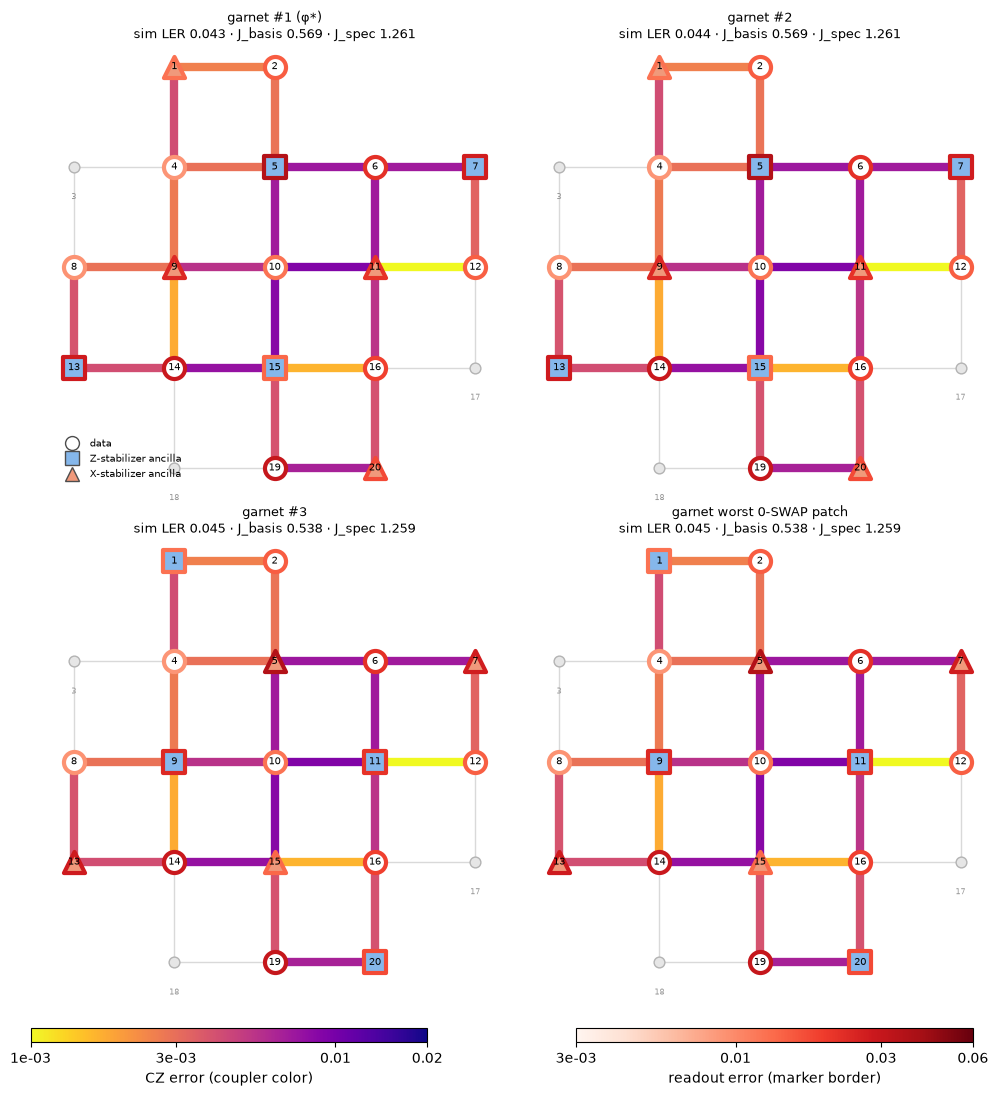

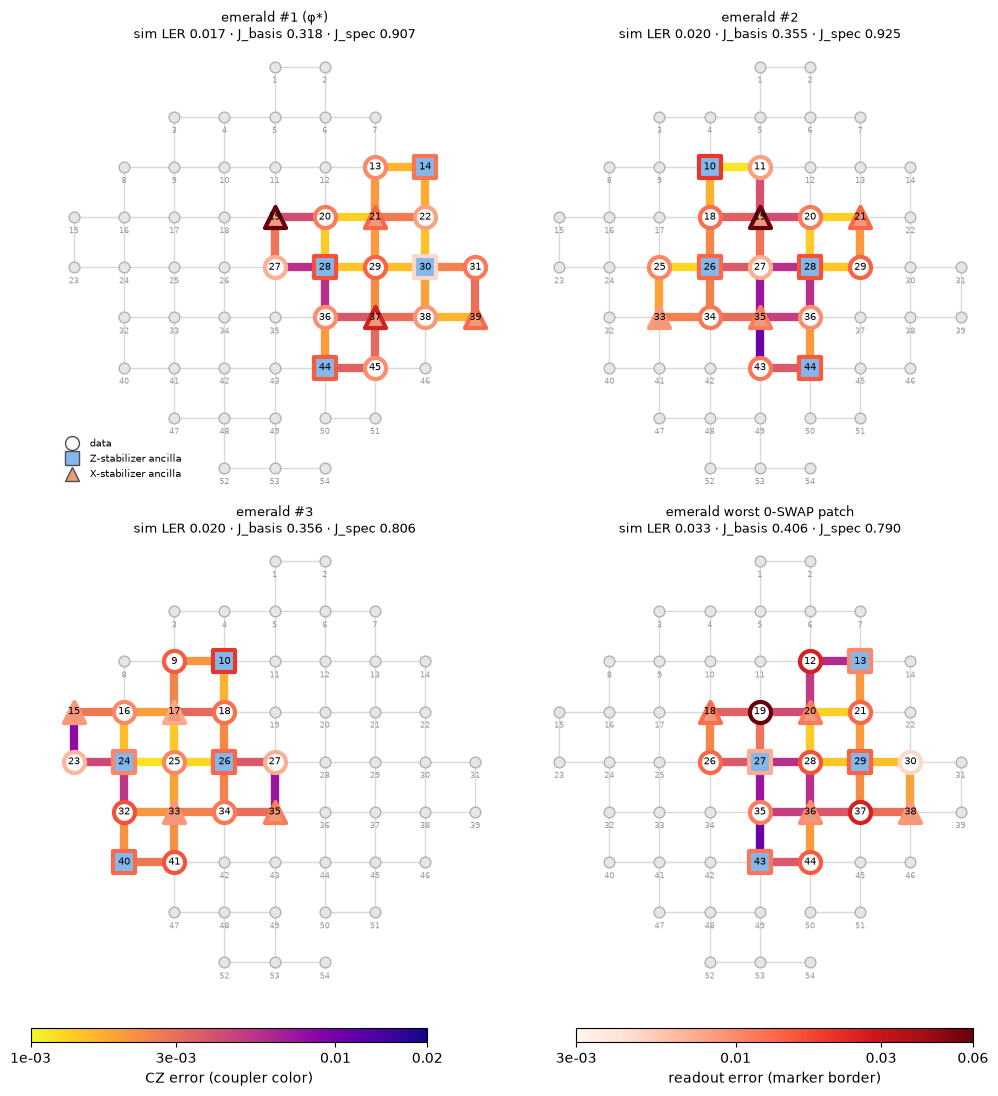

In [13]:
# ── Cell 5: Phase 1 patch overlay on the chip ─────────────────────────────────
# Same visual language as plaquette's LatticeVisualizer in blog-post01 (data vs.
# stabilizer qubits by role), drawn on the physical chip with calibration colors.
from collections import deque

import matplotlib as mpl
from matplotlib.lines import Line2D


def chip_coordinates(qpu):
    """Grid (x, y) per qubit name from the coupling graph: QBn-QB(n±1) is horizontal, else vertical.
    Valid for Garnet and Emerald; falls back to a spring layout if the grid check fails."""
    G = nx.Graph(topologies[qpu]["cz_couplers"])
    num = lambda s: int(re.sub(r"\D", "", s))
    qubits = [n for n in G.nodes if n.startswith("QB")]
    start = min(qubits, key=num)
    pos, todo = {start: (0, 0)}, deque([start])
    while todo:
        a = todo.popleft()
        x, y = pos[a]
        for b in G[a]:
            if b in pos:
                continue
            d = num(b) - num(a)
            pos[b] = (x + d, y) if abs(d) == 1 else (x, y + (1 if d > 0 else -1))
            todo.append(b)
    unit = all(abs(pos[a][0] - pos[b][0]) + abs(pos[a][1] - pos[b][1]) == 1 for a, b in G.edges)
    if not unit or len(set(pos.values())) != len(pos) or len(pos) != len(qubits):
        pos = {k: tuple(v) for k, v in nx.spring_layout(G, seed=1).items()}
    return {k: (x, -y) for k, (x, y) in pos.items()}


def plot_patch(qpu, cand, ax, title, border_metric="e_ro"):
    res, cal = phase1[qpu], calibration[qpu]["qubits"]
    pos_name = chip_coordinates(qpu)
    name_of = dict(zip(cal["idx"].astype(int), cal.index))
    pos = {i: pos_name[n] for i, n in name_of.items() if n in pos_name}
    fp = cand["footprint"]
    qe, ee = fp["qubit_errors"].set_index("phys_idx"), fp["edge_errors"]
    in_patch = set(qe.index)

    cz_norm = mpl.colors.LogNorm(1e-3, 2e-2)
    bd_norm = mpl.colors.LogNorm(3e-3, 6e-2)
    cz_cmap, bd_cmap = mpl.colormaps["plasma_r"], mpl.colormaps["Reds"]

    for u, v in res["hw"]["couplers"].index:              # whole chip, dimmed
        if u in pos and v in pos:
            ax.plot(*zip(pos[u], pos[v]), color="0.85", lw=1, zorder=1)
    for r in ee.itertuples():                              # patch couplers by CZ error
        u, v = r.phys
        ax.plot(*zip(pos[u], pos[v]), color=cz_cmap(cz_norm(r.e_cz)), lw=6, zorder=2,
                solid_capstyle="butt")
    for i, p in pos.items():
        if i not in in_patch:
            ax.scatter(*p, s=60, color="0.9", edgecolor="0.7", zorder=3)
            ax.text(p[0], p[1] - 0.32, name_of[i][2:], ha="center", fontsize=6, color="0.6")

    style = {"data": ("o", "white"), "anc_Z": ("s", "#85B7EB"), "anc_X": ("^", "#F0997B")}
    for i, r in qe.iterrows():
        marker, fill = style[r.role]
        ax.scatter(*pos[i], s=230, marker=marker, color=fill, zorder=4,
                   edgecolor=bd_cmap(bd_norm(max(r[border_metric], 3e-3))), linewidth=3)
        ax.text(pos[i][0], pos[i][1], name_of[i][2:], ha="center", va="center", fontsize=7, zorder=5)

    s = cand["score"]
    sub = f"sim LER {s['ler_sim']:.3f} · J_basis {s['J_basis']:.3f} · J_spec {s['J_spec']:.3f}"
    ax.set_title(f"{qpu} {title}\n{sub}", fontsize=9)
    ax.set_aspect("equal")
    ax.axis("off")
    return cz_norm, cz_cmap, bd_norm, bd_cmap


for qpu, res in phase1.items():
    panels = [(f"#{i+1}" + (" (φ*)" if i == 0 else ""), c) for i, c in enumerate(res["shortlist"])]
    panels.append(("worst 0-SWAP patch", res["worst"]))
    ncol = 2
    nrow = int(np.ceil(len(panels) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(6.2 * ncol, 6.0 * nrow), squeeze=False)
    axes = axes.ravel()
    for ax in axes[len(panels):]:
        ax.axis("off")
    for ax, (title, cand) in zip(axes, panels):
        cz_norm, cz_cmap, bd_norm, bd_cmap = plot_patch(qpu, cand, ax, title)
    fig.subplots_adjust(bottom=0.1, hspace=0.12, wspace=0.02)
    bars = ((cz_norm, cz_cmap, "CZ error (coupler color)", [1e-3, 3e-3, 1e-2, 2e-2]),
            (bd_norm, bd_cmap, "readout error (marker border)", [3e-3, 1e-2, 3e-2, 6e-2]))
    for x0, (norm, cmap, label, ticks) in zip((0.12, 0.56), bars):
        cb = fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), cax=fig.add_axes([x0, 0.05, 0.32, 0.012]),
                          orientation="horizontal", label=label)
        cb.set_ticks(ticks, labels=[f"{t:.0e}" if t < 1e-2 else f"{t:.2f}" for t in ticks])
        cb.ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
    handles = [Line2D([], [], marker=m, ls="", markerfacecolor=f, markeredgecolor="0.3", markersize=10, label=l)
               for l, (m, f) in {"data": ("o", "white"), "Z-stabilizer ancilla": ("s", "#85B7EB"),
                                 "X-stabilizer ancilla": ("^", "#F0997B")}.items()]
    axes[0].legend(handles=handles, loc="lower left", fontsize=7, frameon=False)
    plt.show()

In [14]:
# ── Cell 6: lock the chosen patch and build the hardware circuits ─────────────
qpu = "emerald"                              # the QPU you will run on
best = phase1[qpu]["shortlist"][0]           # panel "#1 (φ*)"
phi_star = best["phi"]                       # {logical qubit -> physical qubit index}
layout = [phi_star[i] for i in range(len(phi_star))]

table = best["footprint"]["qubit_errors"].sort_values("logical_id")
print(table[["logical_id", "stim_q", "role", "phys_idx", "qb_name", "e_ro"]].to_string(index=False))
print("initial_layout =", layout)

# One circuit per round count, all on the same patch (needed for the LER fit)
hardware_circuits = {}
for R in (1, 2, 3, 4, 5):
    stim_R = make_noreset_memory_circuit(PHASE1_CONFIG["distance"], R, PHASE1_CONFIG["basis"])
    bound = bind_and_verify(stim_R, phi_star, backends[qpu], phase1[qpu]["GL"],
                            dict(PHASE1_CONFIG, rounds=R), check_scaling=False)
    hardware_circuits[R] = {"stim": stim_R, "qiskit": bound["transpiled"]}
    print(f"R={R}: checks pass={all(bound['checks'].values())}, CZ={bound['op_counts']['cz']}, depth={bound['depth']}")

 logical_id  stim_q  role  phys_idx qb_name   e_ro
          0       1  data        30    QB31 0.0119
          1       2 anc_X        38    QB39 0.0134
          2       3  data        37    QB38 0.0089
          3       5  data        44    QB45 0.0096
          4       8  data        21    QB22 0.0081
          5       9 anc_Z        29    QB30 0.0047
          6      10  data        28    QB29 0.0142
          7      11 anc_X        36    QB37 0.0259
          8      12  data        35    QB36 0.0096
          9      13 anc_Z        43    QB44 0.0150
         10      14 anc_Z        13    QB14 0.0122
         11      15  data        12    QB13 0.0099
         12      16 anc_X        20    QB21 0.0138
         13      17  data        19    QB20 0.0114
         14      18 anc_Z        27    QB28 0.0162
         15      19  data        26    QB27 0.0071
         16      25 anc_X        18    QB19 0.0602
initial_layout = [30, 38, 37, 44, 21, 29, 28, 36, 35, 43, 13, 12, 20, 19, 27, 26, 

In [16]:
# ── Cell 7: memory circuits — Stim (no-reset) → Qiskit ────────────────────────
# Self-contained: the logic of internal_helpers.py, surface_code.py and stim_to_qiskit.py
# is written out here, nothing is imported from the repo files.
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import RemoveResetInZeroState


# ---- from internal_helpers.py ------------------------------------------------
def get_qubit_lists(circuit):
    """(data qubits, ancilla qubits) of a Stim circuit, as Stim indices.
    Measured qubits with both coordinates odd are data; the rest are ancillas.
    Works for with-reset (MR) and no-reset (M) circuits."""
    coords = circuit.get_final_qubit_coordinates()
    measured = set()
    for instr in circuit.flattened():
        if instr.name in ("M", "MR"):
            measured |= {t.value for t in instr.targets_copy() if t.is_qubit_target}
    data_q, anc_q = [], []
    for q in sorted(measured):
        if q in coords:
            x, y = coords[q]
            (data_q if int(x) % 2 == 1 and int(y) % 2 == 1 else anc_q).append(q)
        else:
            data_q.append(q)          # no coordinates: treat as data (conservative)
    return data_q, anc_q


def get_meas_order(circuit):
    """Stim qubit index of every measurement, in measurement-record order."""
    return [t.value for instr in circuit.flattened() if instr.name in ("M", "MR")
            for t in instr.targets_copy() if t.is_qubit_target]


# ---- from surface_code.py ----------------------------------------------------
def _strip_resets(circ):
    """with-reset -> no-reset: MR -> M, drop the post-MR reset noise, rewrite DETECTORs.
    Without reset the raw readout is m_k = s_k XOR m_(k-1), so every syndrome s_k a
    detector used becomes m_k XOR m_(k-1)."""
    out, n = stim.Circuit(), 0          # n = measurements seen so far
    last_mr, prev_of, just_after_mr = {}, {}, None
    for inst in circ.flattened():       # unroll REPEAT blocks
        name = inst.name
        if name == "MR":
            targets = inst.targets_copy()
            for t in targets:
                prev_of[n] = last_mr.get(t.value)    # previous MR on this qubit (or None)
                last_mr[t.value] = n
                n += 1
            out.append("M", targets, inst.gate_args_copy())   # record without resetting
            just_after_mr = targets
            continue
        if name == "X_ERROR" and just_after_mr is not None and inst.targets_copy() == just_after_mr:
            just_after_mr = None        # this is the post-reset flip noise: the reset is gone
            continue
        just_after_mr = None
        if name == "DETECTOR":
            idx = set()
            for t in inst.targets_copy():
                j = n + t.value         # t.value is negative (rec[-k])
                idx ^= {j}
                if prev_of.get(j) is not None:
                    idx ^= {prev_of[j]}
            out.append("DETECTOR", [stim.target_rec(j - n) for j in sorted(idx)], inst.gate_args_copy())
            continue
        n += inst.num_measurements
        out.append(inst)
    return out


def make_stim_circuit(distance, rounds, basis="Z", no_reset=True, noise=None):
    """Rotated surface-code memory circuit from Stim's generator; no_reset=True gives the
    Emerald/Garnet variant (MR -> M with rewritten detectors)."""
    if basis.upper() not in ("Z", "X"):
        raise ValueError("basis must be 'Z' or 'X'")
    circ = stim.Circuit.generated(f"surface_code:rotated_memory_{basis.lower()}",
                                  distance=distance, rounds=rounds, **(noise or {}))
    return _strip_resets(circ) if no_reset else circ


def get_circuit_info(circuit):
    """Qubit counts and measurement structure, for sanity checks before hardware runs."""
    data_q, anc_q = get_qubit_lists(circuit)
    return dict(num_qubits=circuit.num_qubits, num_data_qubits=len(data_q), num_anc_qubits=len(anc_q),
                num_measurements=circuit.num_measurements, num_detectors=circuit.num_detectors,
                num_observables=circuit.num_observables, data_stim_indices=sorted(data_q),
                anc_stim_indices=sorted(anc_q), meas_order=get_meas_order(circuit))


# ---- from stim_to_qiskit.py --------------------------------------------------
_STIM_SKIP = frozenset({
    "DEPOLARIZE1", "DEPOLARIZE2", "X_ERROR", "Z_ERROR", "Y_ERROR", "PAULI_CHANNEL_1",
    "PAULI_CHANNEL_2", "CORRELATED_ERROR", "ELSE_CORRELATED_ERROR", "DETECTOR",
    "OBSERVABLE_INCLUDE", "QUBIT_COORDS", "SHIFT_COORDS", "TICK",
})


def stim_to_qiskit(stim_circuit):
    """Noiseless Stim circuit -> Qiskit circuit on dense qubits 0..N-1 (sorted Stim indices).
    Classical bit k = Stim measurement k. Returns (qc, stim_to_dense, meas_order)."""
    data_q, anc_q = get_qubit_lists(stim_circuit)
    stim_to_dense = {sq: i for i, sq in enumerate(sorted(set(data_q + anc_q)))}
    qc = QuantumCircuit(len(stim_to_dense), stim_circuit.num_measurements)
    meas_idx, meas_order = 0, []
    for instr in stim_circuit.flattened():
        name = instr.name
        if name in _STIM_SKIP:
            continue
        targets = [t.value for t in instr.targets_copy() if t.is_qubit_target]
        dense = [stim_to_dense[t] for t in targets]
        if name == "R":
            for d in dense:
                qc.reset(d)             # initial resets are removed below (qubits start in |0>)
        elif name == "H":
            for d in dense:
                qc.h(d)
        elif name == "X":
            for d in dense:
                qc.x(d)
        elif name == "CX":
            for a, b in zip(dense[::2], dense[1::2]):
                qc.cx(a, b)
        elif name == "CZ":
            for a, b in zip(dense[::2], dense[1::2]):
                qc.cz(a, b)
        elif name in ("M", "MR"):
            for sq, d in zip(targets, dense):
                qc.measure(d, meas_idx)
                meas_order.append(sq)
                meas_idx += 1
            if name == "MR":            # with-reset circuits only; Emerald cannot run these
                for d in dense:
                    qc.reset(d)
        else:
            raise NotImplementedError(f"[stim_to_qiskit] unhandled gate '{name}'")
    return qc, stim_to_dense, meas_order


QEC_RUN = dict(
    qpu=qpu_3,                          # Emerald: the QPU Phase 1 placed the patch on
    distance=PHASE1_CONFIG["distance"],
    basis="Z",                          # stim_to_qiskit has no RX/MX, so Z memory only
    rounds_list=[1, 2, 3, 4, 5],
    states=[0, 1],                      # |0>_L and |1>_L (T1 makes them differ)
    shots=10_000,
)


def build_memory_circuit(distance, rounds, basis="Z", logical_state=0, noise=None):
    """No-reset rotated-surface-code memory circuit in |0>_L or |1>_L.
    |1>_L: X on all data qubits right after the initial reset (= logical X times X-stabilizers).
    Detectors and the observable stay valid: Stim compares against the noiseless reference."""
    circ = make_stim_circuit(distance, rounds, basis, no_reset=True, noise=noise)
    if logical_state == 0:
        return circ
    if basis.upper() != "Z":
        raise NotImplementedError("logical_state=1 is implemented for the Z basis only")
    data_q, _ = get_qubit_lists(circ)
    out, inserted = stim.Circuit(), False
    for inst in circ.flattened():
        if inst.name == "TICK" and not inserted:   # end of the initial reset layer
            out.append("X", data_q)
            inserted = True
        out.append(inst)
    return out


def stim_to_hardware_qiskit(stim_circ):
    """The conversion from run_qiskit(): stim_to_qiskit, then remove the initial resets
    (qubits start in |0>; IQM has no reset instruction)."""
    qc, stim_to_dense, meas_order = stim_to_qiskit(stim_circ)
    qc = PassManager([RemoveResetInZeroState()]).run(qc)
    assert "reset" not in qc.count_ops(), "mid-circuit reset left: the circuit must be the no-reset variant"
    return qc, stim_to_dense, meas_order


circuits = {}
for state in QEC_RUN["states"]:
    for r in QEC_RUN["rounds_list"]:
        sc = build_memory_circuit(QEC_RUN["distance"], r, QEC_RUN["basis"], state)
        qc, s2d, mo = stim_to_hardware_qiskit(sc)
        circuits[(r, state)] = dict(stim=sc, qc=qc, stim_to_dense=s2d, meas_order=mo)

info = get_circuit_info(circuits[(QEC_RUN["rounds_list"][0], 0)]["stim"])
print(f"d={QEC_RUN['distance']} {QEC_RUN['basis']}-memory: {info['num_data_qubits']} data + "
      f"{info['num_anc_qubits']} ancilla qubits | data {info['data_stim_indices']} | "
      f"ancillas {info['anc_stim_indices']}")
rows = []
for (r, state), c in circuits.items():
    ops = c["qc"].count_ops()
    rows.append(dict(rounds=r, state=f"|{state}>_L", detectors=c["stim"].num_detectors,
                     measurements=c["stim"].num_measurements, cx=ops.get("cx", 0), h=ops.get("h", 0),
                     x=ops.get("x", 0), logical_depth=c["qc"].depth()))
print(pd.DataFrame(rows).to_string(index=False))

d=3 Z-memory: 9 data + 8 ancilla qubits | data [1, 3, 5, 8, 10, 12, 15, 17, 19] | ancillas [2, 9, 11, 13, 14, 16, 18, 25]
 rounds state  detectors  measurements  cx  h  x  logical_depth
      1 |0>_L          8            17  24  8  0              7
      2 |0>_L         16            25  48 16  0             14
      3 |0>_L         24            33  72 24  0             21
      4 |0>_L         32            41  96 32  0             28
      5 |0>_L         40            49 120 40  0             35
      1 |1>_L          8            17  24  8  9              7
      2 |1>_L         16            25  48 16  9             14
      3 |1>_L         24            33  72 24  9             21
      4 |1>_L         32            41  96 32  9             28
      5 |1>_L         40            49 120 40  9             35


In [17]:
# ── Cell 8: syndrome extraction + checks of the no-reset detector algebra ─────
# Self-contained: the logic of extract_syndromes.py and counts_to_measurement_array()
# from internal_helpers.py is written out here.


def counts_to_measurement_array(counts, num_measurements, total_shots):
    """Qiskit counts -> (total_shots, num_measurements) bool in Stim's measurement order.
    Qiskit bitstrings are right-to-left (rightmost character = clbit 0), so each is reversed.
    Identical bitstrings end up next to each other: shot order is lost."""
    result = np.zeros((total_shots, num_measurements), dtype=bool)
    row = 0
    for bitstring, count in counts.items():
        bits = bitstring.replace(" ", "")[::-1]
        meas = np.array([b == "1" for b in bits[:num_measurements]], dtype=bool)
        result[row:row + count] = meas
        row += count
    return result


def extract_syndromes(raw_meas, stim_circuit, print_summary=True):
    """Raw measurements -> detection events and observable flips, using the DETECTOR and
    OBSERVABLE_INCLUDE definitions of the circuit that ran (no-reset detectors included).

    Returns det_events (shots, detectors), obs_flips (shots, observables), raw_meas,
    num_detectors, num_shots, syndrome_weight_per_shot (detectors fired per shot) and
    detector_firing_rate (fraction of shots each detector fired)."""
    converter = stim_circuit.compile_m2d_converter()
    det_events, obs_flips = converter.convert(measurements=raw_meas.astype(bool), separate_observables=True)
    shots, n_det = len(raw_meas), det_events.shape[1]
    weights = det_events.sum(axis=1).astype(int)
    firing = det_events.mean(axis=0)
    if print_summary:
        print("─" * 56)
        print(f"  Shots {shots} | detectors {n_det} | observables {obs_flips.shape[1]}")
        print(f"  Mean syndrome weight {weights.mean():.3f} (max {n_det})")
        print(f"  Shots with 0 detection events: {int((weights == 0).sum())} ({100 * (weights == 0).mean():.1f}%)")
        print(f"  Raw logical flip rate: {obs_flips.mean(axis=0)}")
        hot = [(i, r) for i, r in enumerate(firing) if r > 0.2]
        print(f"  Detectors firing in > 20% of shots: {hot if hot else 'none'}")
        print("─" * 56)
    return dict(det_events=det_events, obs_flips=obs_flips, raw_meas=raw_meas, num_detectors=n_det,
                num_shots=shots, syndrome_weight_per_shot=weights, detector_firing_rate=firing)


def memory_to_measurement_array(memory, num_measurements):
    """Per-shot Qiskit bitstrings (rightmost char = clbit 0) -> (shots, num_measurements) bool,
    in Stim's measurement order and in the order the shots were taken."""
    return np.array([[c == "1" for c in s.replace(" ", "")[::-1][:num_measurements]] for s in memory], dtype=bool)


def counts_to_shuffled_measurements(counts, num_measurements, seed=0):
    """Fallback when only counts exist: counts_to_measurement_array groups identical bitstrings,
    so shuffle before any fold split (shot order is lost either way)."""
    raw = counts_to_measurement_array(counts, num_measurements, sum(counts.values()))
    return raw[np.random.default_rng(seed).permutation(len(raw))]


def detector_formulas(stim_circ, ancilla):
    """Each detector of one ancilla written in raw measurements: m_k = k-th readout of that ancilla,
    'data' = final data readout. Shows d_1 = m_1, d_2 = m_2, d_r = m_r XOR m_(r-2), final detector."""
    meas_q = get_meas_order(stim_circ)
    k_of = [sum(1 for q in meas_q[:i + 1] if q == meas_q[i]) for i in range(len(meas_q))]
    xy = tuple(stim_circ.get_final_qubit_coordinates()[ancilla])
    n, lines = 0, []
    for inst in stim_circ.flattened():
        if inst.name == "DETECTOR" and tuple(inst.gate_args_copy()[:2]) == xy:
            idx = sorted(n + t.value for t in inst.targets_copy())
            terms = [f"m{k_of[i]}" for i in idx if meas_q[i] == ancilla]
            n_data = sum(meas_q[i] != ancilla for i in idx)
            lines.append(f"  t={int(inst.gate_args_copy()[2])}: d = " + " ⊕ ".join(
                terms + ([f"parity of {n_data} final data bits"] if n_data else [])))
        n += inst.num_measurements
    return lines


def trace_injected_error(rounds, stim_qubit, before_round, pauli="X", logical_state=0):
    """Put one certain Pauli error on a qubit before a given round and show what fires."""
    base = build_memory_circuit(QEC_RUN["distance"], rounds, "Z", logical_state)
    _, anc = get_qubit_lists(base)
    out, anc_layers, done = stim.Circuit(), 0, False
    for inst in base.flattened():
        if before_round == 1 and not done and inst.name == "TICK":
            out.append(f"{pauli}_ERROR", [stim_qubit], [1.0])
            done = True
        out.append(inst)
        if inst.name == "M" and {t.value for t in inst.targets_copy()} <= set(anc):
            anc_layers += 1
            if anc_layers == before_round - 1 and not done:
                out.append(f"{pauli}_ERROR", [stim_qubit], [1.0])
                done = True
    det, obs = out.compile_detector_sampler().sample(1, separate_observables=True)
    raw = out.compile_sampler().sample(1)[0]
    coords = out.get_detector_coordinates()
    fired = [tuple(int(v) for v in coords[i]) for i in np.flatnonzero(det[0])]
    print(f"{pauli} on stim qubit {stim_qubit} before round {before_round} ({rounds} rounds, |{logical_state}>_L):")
    print(f"  detectors fired (x, y, t): {fired} | raw logical flip: {bool(obs[0, 0])}")
    meas_q = get_meas_order(out)
    for a in anc:
        if any(tuple(coords[i][:2]) == tuple(out.get_final_qubit_coordinates()[a]) for i in np.flatnonzero(det[0])):
            m = [int(raw[i]) for i, q in enumerate(meas_q) if q == a]
            print(f"  ancilla {a}: raw readouts m_1..m_{rounds} = {m}   (no reset: the record keeps toggling)")


def aer_roundtrip_test(rounds_list=(1, 2, 3), states=(0, 1), shots=200):
    """Noiseless Qiskit simulation of the converted circuits: every detector and the
    observable must be 0 after extract_syndromes (tests conversion + bit order + algebra)."""
    from qiskit_aer import AerSimulator
    sim = AerSimulator(method="stabilizer")
    for state in states:
        for r in rounds_list:
            c = circuits[(r, state)] if (r, state) in circuits else None
            sc = c["stim"] if c else build_memory_circuit(QEC_RUN["distance"], r, "Z", state)
            qc = c["qc"] if c else stim_to_hardware_qiskit(sc)[0]
            mem = sim.run(transpile(qc, sim), shots=shots, memory=True).result().get_memory()
            syn = extract_syndromes(memory_to_measurement_array(mem, sc.num_measurements), sc, print_summary=False)
            ok = syn["det_events"].sum() == 0 and syn["obs_flips"].sum() == 0
            print(f"  noiseless Aer R={r} |{state}>_L: detectors fired {int(syn['det_events'].sum())}, "
                  f"logical flips {int(syn['obs_flips'].sum())} -> {'OK' if ok else 'FAIL'}")
            assert ok


z_anc = [q for q in get_qubit_lists(circuits[(3, 0)]["stim"])[1]
         if q not in {t.value for i in circuits[(3, 0)]["stim"].flattened() if i.name == "H" for t in i.targets_copy()}]
print(f"No-reset detectors of Z-stabilizer ancilla {z_anc[0]} (R=3):")
print("\n".join(detector_formulas(circuits[(3, 0)]["stim"], z_anc[0])))
data_q = get_qubit_lists(circuits[(3, 0)]["stim"])[0]
trace_injected_error(rounds=4, stim_qubit=data_q[4], before_round=1)       # bulk data qubit, flip persists
trace_injected_error(rounds=4, stim_qubit=data_q[4], before_round=2)
aer_roundtrip_test()

No-reset detectors of Z-stabilizer ancilla 9 (R=3):
  t=0: d = m1
  t=1: d = m2
  t=2: d = m1 ⊕ m3
  t=3: d = m2 ⊕ m3 ⊕ parity of 4 final data bits
X on stim qubit 10 before round 1 (4 rounds, |0>_L):
  detectors fired (x, y, t): [(2, 2, 0), (4, 4, 0)] | raw logical flip: False
  ancilla 9: raw readouts m_1..m_4 = [1, 0, 1, 0]   (no reset: the record keeps toggling)
  ancilla 18: raw readouts m_1..m_4 = [1, 0, 1, 0]   (no reset: the record keeps toggling)
X on stim qubit 10 before round 2 (4 rounds, |0>_L):
  detectors fired (x, y, t): [(2, 2, 1), (4, 4, 1)] | raw logical flip: False
  ancilla 9: raw readouts m_1..m_4 = [0, 1, 0, 1]   (no reset: the record keeps toggling)
  ancilla 18: raw readouts m_1..m_4 = [0, 1, 0, 1]   (no reset: the record keeps toggling)
  noiseless Aer R=1 |0>_L: detectors fired 0, logical flips 0 -> OK
  noiseless Aer R=2 |0>_L: detectors fired 0, logical flips 0 -> OK
  noiseless Aer R=3 |0>_L: detectors fired 0, logical flips 0 -> OK
  noiseless Aer R=1 |1>_

In [18]:
# ── Cell 9: place the circuit on the Phase 1 patch (replaces the dummy qubit map) ──
def build_emerald_qubit_map(qpu=None, which="best"):
    """Dense Qiskit index (= sorted Stim qubit = Phase 1 logical id) -> physical Qiskit index.
    which: "best" (phi*), "worst" (A/B control) or an int k for shortlist[k]."""
    res = phase1[qpu or QEC_RUN["qpu"]]
    cand = {"best": res["shortlist"][0], "worst": res["worst"]}.get(which) \
        if isinstance(which, str) else res["shortlist"][which]
    # the dense order used by stim_to_qiskit must be the order Phase 1 mapped
    gl = {res["GL"][n]["stim_q"]: res["GL"][n]["logical_id"] for n in res["GL"].node_indices()}
    s2d = next(iter(circuits.values()))["stim_to_dense"]
    assert all(gl[sq] == d for sq, d in s2d.items()), "dense qubit order differs from Phase 1"
    return {int(k): int(v) for k, v in cand["phi"].items()}


def print_qubit_map(stim_circ, qubit_map, qpu=None):
    """Stim -> dense -> physical table, plus a check that every CX pair is a real coupler
    (works anywhere on the chip, unlike the stride-based version)."""
    qpu = qpu or QEC_RUN["qpu"]
    hw_q = phase1[qpu]["hw"]["qubits"]
    coords = stim_circ.get_final_qubit_coordinates()
    data_q, anc_q = get_qubit_lists(stim_circ)
    h_targets = {t.value for i in stim_circ.flattened() if i.name == "H" for t in i.targets_copy()}
    stim_to_dense = {sq: i for i, sq in enumerate(sorted(set(data_q + anc_q)))}
    rows = []
    for sq, d in stim_to_dense.items():
        role = "data" if sq in data_q else ("anc_X" if sq in h_targets else "anc_Z")
        rows.append(dict(stim_q=sq, coord=tuple(int(v) for v in coords[sq]), role=role, dense=d,
                         qiskit=qubit_map[d], QB=hw_q.loc[qubit_map[d], "qb_name"]))
    print(pd.DataFrame(rows).to_string(index=False))
    edges = {tuple(sorted(e)) for e in backends[qpu].coupling_map.get_edges()}
    pairs = {tuple(sorted((qubit_map[stim_to_dense[a]], qubit_map[stim_to_dense[b]])))
             for i in stim_circ.flattened() if i.name == "CX"
             for a, b in zip(*[iter([t.value for t in i.targets_copy()])] * 2)}
    bad = sorted(pairs - edges)
    print(f"CX pairs: {len(pairs) - len(bad)} on real couplers, {len(bad)} need SWAPs {bad}")


def transpile_on_patch(qc, qubit_map, backend, optimization_level=1, seed=7):
    """Transpile onto the fixed patch; routing is disabled, so any placement that would
    need a SWAP raises. Then check the result before it can reach the QPU."""
    layout = [qubit_map[i] for i in range(qc.num_qubits)]
    qc_t = transpile(qc, backend, initial_layout=layout, routing_method="none",
                     optimization_level=optimization_level, seed_transpiler=seed)
    used = list(qc_t.layout.initial_index_layout(filter_ancillas=True))
    edges = {tuple(sorted(e)) for e in backend.coupling_map.get_edges()}
    twoq = [tuple(sorted((qc_t.find_bit(i.qubits[0]).index, qc_t.find_bit(i.qubits[1]).index)))
            for i in qc_t.data if i.operation.num_qubits == 2 and i.operation.name != "barrier"]
    want_meas = [(layout[qc.find_bit(i.qubits[0]).index], qc.find_bit(i.clbits[0]).index)
                 for i in qc.data if i.operation.name == "measure"]
    got_meas = [(qc_t.find_bit(i.qubits[0]).index, qc_t.find_bit(i.clbits[0]).index)
                for i in qc_t.data if i.operation.name == "measure"]
    ops = dict(qc_t.count_ops())
    n_2q = qc.count_ops().get("cx", 0) + qc.count_ops().get("cz", 0)
    checks = {
        "layout_kept": used == layout,
        "no_extra_2q_gates": len(twoq) == n_2q and ops.get("cz", 0) == n_2q,   # SWAPs would add CZs
        "all_2q_on_patch_couplers": all(p in edges and set(p) <= set(layout) for p in twoq),
        "measurements_aligned": sorted(got_meas, key=lambda x: x[1]) == sorted(want_meas, key=lambda x: x[1]),
        "no_reset": "reset" not in ops,
    }
    failed = [k for k, v in checks.items() if not v]
    if failed:
        raise AssertionError(f"transpile_on_patch failed: {failed}")
    return qc_t, dict(layout=layout, checks=checks, ops=ops, depth=qc_t.depth(),
                      logical_depth=qc.depth(), n_1q=sum(v for k, v in ops.items() if k == "r"))


qubit_map = build_emerald_qubit_map()
print_qubit_map(circuits[(3, 0)]["stim"], qubit_map)
for lvl in (1, 3):
    qc_t, rep = transpile_on_patch(circuits[(3, 0)]["qc"], qubit_map, backends[QEC_RUN["qpu"]], lvl)
    print(f"optimization_level={lvl}: depth {rep['depth']} (logical {rep['logical_depth']}) | "
          f"CZ {rep['ops'].get('cz')} | single-qubit r gates {rep['n_1q']} | checks passed")

 stim_q  coord  role  dense  qiskit   QB
      1 (1, 1)  data      0      30 QB31
      2 (2, 0) anc_X      1      38 QB39
      3 (3, 1)  data      2      37 QB38
      5 (5, 1)  data      3      44 QB45
      8 (1, 3)  data      4      21 QB22
      9 (2, 2) anc_Z      5      29 QB30
     10 (3, 3)  data      6      28 QB29
     11 (4, 2) anc_X      7      36 QB37
     12 (5, 3)  data      8      35 QB36
     13 (6, 2) anc_Z      9      43 QB44
     14 (0, 4) anc_Z     10      13 QB14
     15 (1, 5)  data     11      12 QB13
     16 (2, 4) anc_X     12      20 QB21
     17 (3, 5)  data     13      19 QB20
     18 (4, 4) anc_Z     14      27 QB28
     19 (5, 5)  data     15      26 QB27
     25 (4, 6) anc_X     16      18 QB19
CX pairs: 24 on real couplers, 0 need SWAPs []
optimization_level=1: depth 25 (logical 21) | CZ 72 | single-qubit r gates 106 | checks passed
optimization_level=3: depth 25 (logical 21) | CZ 72 | single-qubit r gates 106 | checks passed


In [19]:
# ── Cell 10: hardware execution on the Phase 1 patch ──────────────────────────
try:
    from iqm.iqm_client import CircuitCompilationOptions, DDMode
except ImportError:                     # older/newer client layouts: run without these options
    CircuitCompilationOptions = DDMode = None

RUN_DIR = pathlib.Path("hardware_runs")
RUN_DIR.mkdir(exist_ok=True)


def run_qiskit(rounds=1, shots=None, logical_state=0, qpu=None, which="best",
               distance=None, dd=False, max_duration_over_t2=None, opt_level=1, save_prefix="syndromes"):
    """Stim circuit -> Qiskit -> transpile on the Phase 1 patch -> run -> per-shot bits
    -> extract_syndromes(). Uses the backend from Cell 1 (token from .env, never passed here).

    which               : "best" (phi*), "worst" (A/B control) or shortlist index
    dd                  : IQM dynamical decoupling (DDMode.ENABLED) for A/B tests
    max_duration_over_t2: IQM rejects circuits longer than this x shortest T2 of the patch;
                          None = server default, 0.0 = no check (long round counts may need it)
    """
    qpu = qpu or QEC_RUN["qpu"]
    distance = distance or QEC_RUN["distance"]
    shots = shots or QEC_RUN["shots"]
    backend = backends[qpu]

    stim_circ = build_memory_circuit(distance, rounds, "Z", logical_state)     # defines the detectors
    qc, stim_to_dense, meas_order = stim_to_hardware_qiskit(stim_circ)
    qmap = build_emerald_qubit_map(qpu, which)
    qc_t, rep = transpile_on_patch(qc, qmap, backend, opt_level)
    print(f"R={rounds} |{logical_state}>_L on {which} patch: depth {rep['depth']} (logical {rep['logical_depth']}), "
          f"CZ {rep['ops'].get('cz')} (= {qc.count_ops().get('cx', 0)} CX, no SWAPs), r gates {rep['n_1q']}")

    run_kwargs = dict(shots=shots)
    if CircuitCompilationOptions is not None and (dd or max_duration_over_t2 is not None):
        run_kwargs["circuit_compilation_options"] = CircuitCompilationOptions(
            max_circuit_duration_over_t2=max_duration_over_t2,
            dd_mode=DDMode.ENABLED if dd else DDMode.DISABLED)
    job = backend.run(qc_t, **run_kwargs)
    print("  job id:", job.job_id())
    result = job.result()

    try:                                                    # per-shot results keep shot order
        raw_meas = memory_to_measurement_array(result.get_memory(), stim_circ.num_measurements)
        order = "per-shot memory"
    except Exception:
        raw_meas = counts_to_shuffled_measurements(result.get_counts(), stim_circ.num_measurements)
        order = "counts (shuffled)"

    syndromes = extract_syndromes(raw_meas, stim_circ, print_summary=False)     # circuit that actually ran
    syndromes.update(
        physical_qubits=np.array(rep["layout"]), rounds=rounds, logical_state=logical_state,
        distance=distance, qpu=qpu, patch=str(which), dd=dd, shot_order=order,
        job_id=str(job.job_id()),
        calibration_set_id=str(getattr(result.results[0], "calibration_set_id", None)),
        phase1_calibration_set_id=calibration[qpu]["calibration_set_id"],
        transpiled_depth=rep["depth"], transpiled_cz=rep["ops"].get("cz", 0), transpiled_r=rep["n_1q"],
    )
    path = RUN_DIR / f"{save_prefix}_{qpu}_{which}_d{distance}_r{rounds}_s{logical_state}{'_dd' if dd else ''}.npz"
    np.savez_compressed(path, **{k: np.asarray(v) for k, v in syndromes.items()})
    print(f"  {order}: {syndromes['num_shots']} shots | mean detectors fired/shot "
          f"{syndromes['syndrome_weight_per_shot'].mean():.2f} | raw logical flips "
          f"{syndromes['obs_flips'].mean():.4f} | saved {path}")
    return syndromes

In [20]:
# ── Cell 11: noise models, decoding, LER fit, simulation rehearsal, analysis ──
import glob
from scipy.optimize import curve_fit

# Uniform circuit noise for quick tests. The repo's run_on_hardware.py used 0.03, which is
# above the surface-code threshold (every decoder ends near P = 0.5), so 0.003 is used here.
DEFAULT_NOISE = dict(
    after_clifford_depolarization=0.003,
    after_reset_flip_probability=0.003,
    before_measure_flip_probability=0.003,
    before_round_data_depolarization=0.003,
)


def with_record_readout(circ, p):
    """Add readout misassignment (recorded bit flipped, qubit state untouched) to every M.
    Stim's generated noise only flips the state before M, which in a no-reset circuit makes
    lag-1 edges only; misassignment creates the lag-2 edges hardware also has."""
    out = stim.Circuit()
    for inst in circ.flattened():
        out.append("M", inst.targets_copy(), [p]) if inst.name == "M" and not inst.gate_args_copy() \
            else out.append(inst)
    return out


def calibration_noise_circuit(stim_circ, fp, readout_state_fraction=0.5):
    """Phase 1 error footprint on the exact circuit that ran (any rounds, |0> or |1>).
    Ancilla readout error is split into a state flip (lag-1) and a misassignment (lag-2),
    so every edge type exists in the decoding graph; Phase 2 learning re-weights them."""
    qe = fp["qubit_errors"].set_index("stim_q")
    st = dict(zip(fp["qubit_errors"].logical_id, fp["qubit_errors"].stim_q))
    e_cz = {tuple(sorted((st[a], st[b]))): e for (a, b), e in zip(fp["edge_errors"].logical, fp["edge_errors"].e_cz)}
    anc = set(qe.index[qe.role != "data"])
    out = stim.Circuit()
    for inst in stim_circ.without_noise().flattened():
        name, tg = inst.name, [t.value for t in inst.targets_copy() if t.is_qubit_target]
        if name == "M":
            for q in tg:
                p = float(qe.e_ro[q])
                if q in anc:
                    out.append("X_ERROR", [q], [readout_state_fraction * p])
                    out.append("M", [q], [(1 - readout_state_fraction) * p])
                else:
                    out.append("M", [q], [p])
            if set(tg) <= anc:                              # one round of idling per ancilla readout
                for q in qe.index:
                    out.append("PAULI_CHANNEL_1", [q], [qe.p_x[q], qe.p_y[q], qe.p_z[q]])
            continue
        out.append(inst)
        if name == "CX":
            for a, b in zip(tg[::2], tg[1::2]):
                out.append("DEPOLARIZE2", [a, b], [e_cz[tuple(sorted((a, b)))]])
        elif name in ("H", "X"):
            for q in tg:
                out.append("DEPOLARIZE1", [q], [qe.e_1q[q]])
    return out


def uniform_dem(dem, p=0.01):
    """Same graph, every mechanism equally likely (Baseline 1: uniform MWPM)."""
    out = stim.DetectorErrorModel()
    for inst in dem.flattened():
        out.append("error", p, inst.targets_copy()) if inst.type == "error" else out.append(inst)
    return out


def decoder_dem(rounds, logical_state, model="calibration", which="best", noise=None):
    """model: "calibration" (Baseline 2, Phase 1 footprint), "uniform" (Baseline 1, same graph,
    equal weights) or "default" (DEFAULT_NOISE plus readout misassignment)."""
    base = build_memory_circuit(QEC_RUN["distance"], rounds, "Z", logical_state)
    if model == "default":
        nz = noise or DEFAULT_NOISE
        noisy = with_record_readout(build_memory_circuit(QEC_RUN["distance"], rounds, "Z", logical_state, nz),
                                    nz["before_measure_flip_probability"])
        return noisy.detector_error_model(decompose_errors=True)
    res = phase1[QEC_RUN["qpu"]]
    fp = (res["worst"] if which == "worst" else res["shortlist"][0 if which == "best" else which])["footprint"]
    dem = calibration_noise_circuit(base, fp).detector_error_model(decompose_errors=True)
    return uniform_dem(dem) if model == "uniform" else dem


def decode_hardware_results(syndromes, model="calibration", which=None, noise=None):
    """PyMatching on a DEM whose detectors match the circuit that ran. Returns (P_error, 1-sigma)."""
    rounds, state = int(syndromes["rounds"]), int(syndromes["logical_state"])
    dem = decoder_dem(rounds, state, model, which or str(syndromes.get("patch", "best")), noise)
    det, obs = np.asarray(syndromes["det_events"]), np.asarray(syndromes["obs_flips"]).astype(bool)
    assert det.shape[1] == dem.num_detectors, f"data has {det.shape[1]} detectors, DEM {dem.num_detectors}"
    pred = pymatching.Matching.from_detector_error_model(dem).decode_batch(det).astype(bool)
    n = len(det)
    ler = float(np.mean(np.any(pred != obs, axis=1)))
    err = float(np.sqrt(ler * (1 - ler) / n + 1 / (4 * n * n)))     # never 0, even with 0 failures
    return ler, err


def _p_model(x, e):
    """P_error after x rounds for a per-round logical error rate e (README form, A = 1)."""
    return 0.5 * (1 - (1 - 2 * e) ** x)


def _p_model_A(x, e, A):
    """Same with a free amplitude: (1 - A)/2 is the round-independent prep/readout part."""
    return 0.5 * (1 - A * (1 - 2 * e) ** x)


def _fit_eps(rounds, ler, err, shots):
    """Weighted fits of both forms. Points with P >= 0.45 carry almost no information."""
    rounds, ler = np.asarray(rounds), np.asarray(ler)
    err = np.maximum(np.asarray(err), 1.0 / shots)
    use = ler < 0.45
    n, p, s = rounds[use], ler[use], err[use]
    guess = float(np.clip((1 - (1 - 2 * p[0]) ** (1 / n[0])) / 2, 1e-6, 0.4))
    popt, pcov = curve_fit(_p_model, n, p, p0=[guess], sigma=s, absolute_sigma=True, bounds=(0, 0.5))
    fit = dict(eps=float(popt[0]), eps_err=float(np.sqrt(pcov[0, 0])),
               chi2=float(np.sum(((p - _p_model(n, popt[0])) / s) ** 2)), dof=len(n) - 1, pts=(n, p, s))
    if len(n) >= 3:
        pa, ca = curve_fit(_p_model_A, n, p, p0=[guess, 1.0], sigma=s, absolute_sigma=True,
                           bounds=([0, 0.5], [0.5, 1.5]))
        fit.update(eps_A=float(pa[0]), eps_A_err=float(np.sqrt(ca[0, 0])), A=float(pa[1]),
                   A_err=float(np.sqrt(ca[1, 1])))
    return fit


def _report_and_plot(fit, ax, label):
    extra = (f" | A-free: eps_L = {fit['eps_A']:.5f} ± {fit['eps_A_err']:.5f}, A = {fit['A']:.3f}"
             if "A" in fit else "")
    print(f"[{label}] eps_L = {fit['eps']:.5f} ± {fit['eps_err']:.5f}  chi2/dof = {fit['chi2']:.1f}/{fit['dof']}{extra}")
    ax = plt.gca() if ax is None else ax
    n, p, s = fit["pts"]
    grid = np.linspace(0, n.max() * 1.05, 200)
    data = ax.errorbar(n, p, yerr=s, fmt="o", capsize=3, label=f"{label} data")
    ax.plot(grid, _p_model(grid, fit["eps"]), color=data[0].get_color(), label=f"{label}: eps = {fit['eps']:.4f}")
    ax.set_xlabel("rounds"); ax.set_ylabel("P_error"); ax.legend(fontsize=8)


def logical_error_rate_stim(rounds_list=None, logical_state=0, shots=100_000, sim_model="calibration",
                            decoder_model="calibration", which="best", noise=None, seed=1, ax=None, label=None):
    """Full pipeline rehearsal: simulated raw bits -> extract_syndromes -> decode -> fit.
    sim_model is what the 'device' does, decoder_model what the decoder assumes; making them
    differ shows what a wrong model costs."""
    rounds_list = np.asarray(rounds_list or QEC_RUN["rounds_list"])
    ler, err = [], []
    for r in rounds_list:
        hw = build_memory_circuit(QEC_RUN["distance"], int(r), "Z", logical_state)        # defines detectors
        if sim_model == "default":
            nz = noise or DEFAULT_NOISE
            sim = with_record_readout(build_memory_circuit(QEC_RUN["distance"], int(r), "Z", logical_state, nz),
                                      nz["before_measure_flip_probability"])
        else:
            res = phase1[QEC_RUN["qpu"]]
            fp = (res["worst"] if which == "worst" else res["shortlist"][0])["footprint"]
            sim = calibration_noise_circuit(hw, fp)
        raw = sim.compile_sampler(seed=seed).sample(shots)
        syn = extract_syndromes(raw, hw, print_summary=False)
        syn.update(rounds=int(r), logical_state=logical_state, patch=which)
        p, e = decode_hardware_results(syn, decoder_model, which, noise)
        ler.append(p); err.append(e)
    fit = _fit_eps(rounds_list, ler, err, shots)
    _report_and_plot(fit, ax, label or f"sim |{logical_state}>, {sim_model} device, {decoder_model} decoder")
    return fit, np.array(ler), np.array(err)


def load_runs(save_prefix="syndromes", qpu=None, which="best", logical_state=0, dd=False):
    """{rounds: syndromes dict} for the saved runs of one patch and state, sorted by rounds."""
    qpu = qpu or QEC_RUN["qpu"]
    runs = {}
    pattern = RUN_DIR / f"{save_prefix}_{qpu}_{which}_d{QEC_RUN['distance']}_r*_s{logical_state}{'_dd' if dd else ''}.npz"
    for path in glob.glob(str(pattern)):
        n = int(re.search(r"_r(\d+)_s", path).group(1))
        with np.load(path, allow_pickle=False) as f:
            runs[n] = {k: f[k] for k in f.files}
        for k in ("num_shots", "num_detectors", "rounds", "logical_state"):
            runs[n][k] = int(runs[n][k])
        runs[n]["patch"] = str(runs[n]["patch"])
    return dict(sorted(runs.items()))


def analyse_saved_runs(logical_state=0, which="best", model="calibration", dd=False,
                       save_prefix="syndromes", show_diagnostics=True, ax=None):
    """Re-decode every saved run of one patch/state, fit eps_L, run consistency checks, plot."""
    runs = load_runs(save_prefix, which=which, logical_state=logical_state, dd=dd)
    if not runs:
        raise FileNotFoundError(f"no saved runs for patch={which}, state={logical_state}, dd={dd}")
    rounds = np.array(list(runs))
    ler, err, raw_flip = [], [], []
    for n, syn in runs.items():
        p, e = decode_hardware_results(syn, model, which)
        ler.append(p); err.append(e); raw_flip.append(float(np.mean(syn["obs_flips"])))
        print(f"R={n:>2}: {syn['num_shots']:>6} shots ({syn['shot_order']}) | decoded P_error = {p:.4f} ± {e:.4f} "
              f"| undecoded flips = {raw_flip[-1]:.4f}")
    shots = min(s["num_shots"] for s in runs.values())

    layouts = {tuple(int(q) for q in s["physical_qubits"]) for s in runs.values()}
    calsets = {str(s["calibration_set_id"]) for s in runs.values()}
    if len(layouts) > 1:
        print(f"WARNING: {len(layouts)} different physical layouts across rounds")
    if len(calsets) > 1:
        print(f"WARNING: runs span {len(calsets)} calibration sets: {calsets}")

    fit = _fit_eps(rounds, ler, err, shots)
    if show_diagnostics:
        fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
        _report_and_plot(fit, axs[0], f"|{logical_state}>_L {which} ({model} decoder)")
        axs[0].plot(rounds, raw_flip, "s", mfc="none", color="gray", label="undecoded flips")
        axs[0].legend(fontsize=8); axs[0].set_title("logical error vs rounds")
        rate = []
        for n, s in runs.items():                       # interior rounds only (edges differ)
            c = build_memory_circuit(QEC_RUN["distance"], n, "Z", logical_state).get_detector_coordinates()
            tt = np.array([c[i][2] for i in range(len(c))])
            sel = (tt > 0) & (tt < n)
            rate.append(float(np.asarray(s["detector_firing_rate"])[sel].mean()) if sel.any() else np.nan)
        axs[1].plot(rounds, rate, "o-"); axs[1].set_xlabel("rounds")
        axs[1].set_ylabel("mean firing rate, interior rounds"); axs[1].set_title("drift check (flat = stable)")
        n_max = int(rounds.max())
        c = build_memory_circuit(QEC_RUN["distance"], n_max, "Z", logical_state).get_detector_coordinates()
        t = np.array([c[i][2] for i in range(len(c))])
        fr = np.asarray(runs[n_max]["detector_firing_rate"])
        axs[2].plot(sorted(set(t)), [fr[t == k].mean() for k in sorted(set(t))], "o-")
        axs[2].set_xlabel("round index"); axs[2].set_ylabel("mean detector firing rate")
        axs[2].set_title(f"inside the {n_max}-round run")
        fig.tight_layout()
        plt.show()
    else:
        _report_and_plot(fit, ax, f"|{logical_state}>_L {which} ({model} decoder)")
    return dict(rounds=rounds, ler=np.array(ler), err=np.array(err), raw_flip=np.array(raw_flip),
                fit=fit, layouts=layouts, calibration_sets=calsets)

[sim |0>, calibration device, calibration decoder] eps_L = 0.00660 ± 0.00007  chi2/dof = 9.4/4 | A-free: eps_L = 0.00647 ± 0.00013, A = 0.999
[sim |1>, calibration device, calibration decoder] eps_L = 0.00664 ± 0.00007  chi2/dof = 20.5/4 | A-free: eps_L = 0.00651 ± 0.00013, A = 0.999


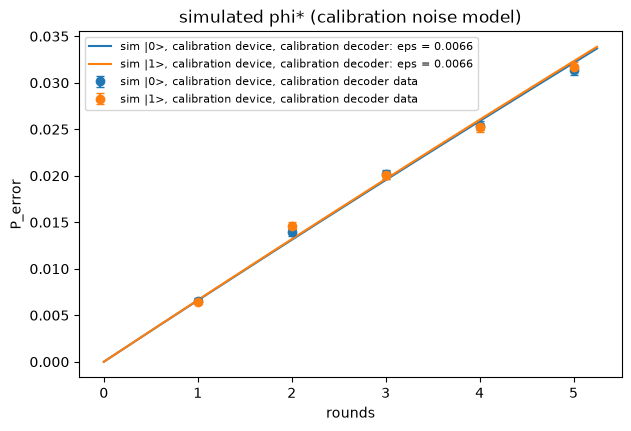

no saved runs for patch=best, state=0, dd=False
no saved runs for patch=best, state=1, dd=False


In [21]:
# ── Cell 12: rehearse in simulation, then run the hardware batch, then analyse ─
RUN_ON_HARDWARE = False          # True only when you are ready to spend QPU credits
RUN_WORST_PATCH_CONTROL = False  # A/B control: the worst 0-SWAP patch, fewer shots
CONTROL_ROUNDS, CONTROL_SHOTS = [1, 3], 3_000

# 1) Offline rehearsal on phi*'s calibration noise model (no QPU time)
fig, ax = plt.subplots(figsize=(7, 4.5))
sim_fits = {s: logical_error_rate_stim(logical_state=s, ax=ax)[0] for s in QEC_RUN["states"]}
ax.set_title("simulated phi* (calibration noise model)"); plt.show()

# 2) Hardware batch
if RUN_ON_HARDWARE:
    qpu = QEC_RUN["qpu"]
    try:
        if calibration_changed(qpu):
            raise RuntimeError("IQM recalibrated since Cell 3: re-run Cells 3-6 before this batch")
    except AttributeError:
        pass
    n_jobs = len(QEC_RUN["rounds_list"]) * len(QEC_RUN["states"])
    print(f"Submitting {n_jobs} circuits x {QEC_RUN['shots']} shots on {qpu} (phi*)")
    for state in QEC_RUN["states"]:
        for r in QEC_RUN["rounds_list"]:
            run_qiskit(rounds=r, logical_state=state)
    if RUN_WORST_PATCH_CONTROL:
        for state in QEC_RUN["states"]:
            for r in CONTROL_ROUNDS:
                run_qiskit(rounds=r, logical_state=state, which="worst", shots=CONTROL_SHOTS)

# 3) Analysis of whatever has been saved (works later without reconnecting)
hardware_results = {}
for state in QEC_RUN["states"]:
    try:
        hardware_results[state] = analyse_saved_runs(logical_state=state)
    except FileNotFoundError as err:
        print(err)
if len(hardware_results) == 2:
    e0, e1 = (hardware_results[s]["fit"] for s in (0, 1))
    eps = (e0["eps"] + e1["eps"]) / 2
    print(f"average over |0>_L and |1>_L: eps_L = {eps:.5f} ± {np.hypot(e0['eps_err'], e1['eps_err']) / 2:.5f}")